# Does credit card use improve the model?

This notebook adds the 15 features from `11_credit_card_eda_features.ipynb` to the model built in `08_model_with_installments.ipynb`, and measures whether the model gets better. It is the last history table.

## Where things stand

| Model | Features | Cross-validation | Kaggle private |
|---|---:|---:|---:|
| Application only (notebook 02) | 36 | 0.7685 | 0.7638 |
| With the credit bureau (notebook 04) | 60 | 0.7779 | 0.7753 |
| With earlier applications (notebook 06) | 85 | 0.7856 | 0.7842 |
| With the payment record (notebook 08) | 108 | 0.7932 | 0.7934 |
| Monthly balances of cash and point-of-sale loans (notebook 10) | | +0.00007 | left out |

The model to beat is notebook 08's.

## The expectation, written in notebook 11 before this notebook was started

A gain, likely larger than notebook 10's and smaller than notebook 08's. The card features are the strongest any history table has produced and keep a signal of 0.54 to 0.55 beyond the current model, but they describe only the 28% of applicants with a card. Notebook 11 also warned that the card features differ between train and test more than any earlier table.

## What counts as an improvement

The four conditions of notebooks 04, 06, 08 and 10, unchanged: the mean ROC AUC is higher; higher in at least four of five folds; the gain is more than twice its standard error; and the gain exceeds the seed noise floor (0.0005, or larger if stage 2 measures more).

## What this notebook does, and when it stops

| # | Stage | Question it answers |
|---|---|---|
| 1 | Setup, join and audit | Do the feature tables join exactly, and is the split unchanged? |
| 2 | Baseline | Does the current 108-feature model still score 0.7932 when rebuilt here? |
| 3 | Add the new features | With every setting unchanged, what is the gain, and does it meet the four conditions? |

**The rule fixed in notebook 10, kept.** If stage 3 does not meet the four conditions, the table is left out and the notebook ends with a short look at who, if anyone, gains. If it does meet them, the notebook continues with the sequence of notebook 08: where the gain comes from, pruning, settings, calibration, explanations, and outputs with a diagnostic submission without the features that carry a shift warning.

## Rules followed throughout

The same folds for every comparison; the holdout stays closed; Kaggle scores are never used to choose; everything that learns from the outcome sits inside the pipeline; a control with the new columns scrambled between applicants.

## Warnings carried in from notebook 11

- Test applicants hold cards more often (34% against 28%) and used them a little less.
- Three kept features carry warnings: `CC_LIMIT_LATEST` and `CC_N_DEMAND` for shift, `CC_SHARE_ATM` for differing in fine detail.
- The redundancy rule of notebook 11 dropped the best single candidate, utilisation in the latest month, in favour of a near-copy with wider coverage.

## Stage 1: Setup, join and audit

No model is fitted in this stage.

In [1]:
import ast, hashlib, inspect, json, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import nbformat
import joblib
import lightgbm, sklearn, scipy
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, train_test_split

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 220)

PROCESSED, RAW = '../data/processed', '../data/raw'
CACHE_DIR = Path('../artifacts/cv_cache_12')
sys.path.insert(0, '../src/models')
import pipeline as shared
from pipeline import SEED, N_SPLITS, CategoryEncoder, KeepColumns, CalibratedModel, lgbm_model, make_pipeline, cross_validate, compare, score_predictions, logit

# 1.1 the six pieces copied from notebook 02 are still identical to their source there
notebook_02 = nbformat.read('02_model_selection_training.ipynb', 4)
original = {}
for cell in notebook_02.cells:
    if cell.cell_type != 'code':
        continue
    try:
        tree = ast.parse(cell.source)
    except SyntaxError:
        continue
    for node in tree.body:
        if isinstance(node, (ast.ClassDef, ast.FunctionDef)):
            original.setdefault(node.name, []).append(ast.get_source_segment(cell.source, node))
COPIED = ['CategoryEncoder', 'KeepColumns', 'CalibratedModel', 'logit', 'score_predictions', 'describe']
fidelity = {name: len(original.get(name, [])) == 1 and original[name][0].strip() == inspect.getsource(getattr(shared, name)).strip() for name in COPIED}
print('identical to notebook 02:', fidelity)
assert all(fidelity.values())
MODULE_CHECKSUM = hashlib.md5(Path('../src/models/pipeline.py').read_bytes()).hexdigest()
print(f"module checksum {MODULE_CHECKSUM[:12]} (the module has not changed since notebook 04, which notebooks 06, 08 and 10 also used, if this is 1379a001d7bb: {MODULE_CHECKSUM.startswith('1379a001d7bb')})")
print(f"results are cached in {CACHE_DIR.as_posix().replace('../', '')}")

identical to notebook 02: {'CategoryEncoder': True, 'KeepColumns': True, 'CalibratedModel': True, 'logit': True, 'score_predictions': True, 'describe': True}
module checksum 1379a001d7bb (the module has not changed since notebook 04, which notebooks 06, 08 and 10 also used, if this is 1379a001d7bb: True)
results are cached in artifacts/cv_cache_12


In [2]:
recipe = json.loads(Path('../artifacts/model_with_installments/metadata.json').read_text(encoding='utf-8'))
CURRENT = list(recipe['features'])                                    # the 108 features of the current model
SOURCES = {k: list(v) for k, v in recipe['feature_sources'].items()}
BEST_PARAMS = dict(recipe['training']['lightgbm_settings'])
N_TREES, LEARNING_RATE = int(recipe['training']['trees']), float(recipe['training']['learning_rate'])
REFERENCE_CV = recipe['evidence']['cross_validation']
THRESHOLD = float(recipe['decision']['reference_threshold'])

def FINAL():
    return lgbm_model(BEST_PARAMS, N_TREES, LEARNING_RATE)

print(f"current model: {len(CURRENT)} features {({k: len(v) for k, v in SOURCES.items()})}, {N_TREES:,} trees, learning rate {LEARNING_RATE}, seed {recipe['training']['seed']}")
print(f"its cross-validated scores in notebook 08: ROC AUC {REFERENCE_CV['roc_auc']:.5f}, PR AUC {REFERENCE_CV['pr_auc']:.5f}, log loss {REFERENCE_CV['log_loss']:.5f} (after calibration)")
versions_now = {'python': sys.version.split()[0], 'lightgbm': lightgbm.__version__, 'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__, 'scipy': scipy.__version__}
assert recipe['versions'] == versions_now and recipe['training']['seed'] == SEED and len(CURRENT) == 108 and N_TREES == 3500
print('library versions as when the model was saved:', versions_now)

current model: 108 features {'application': 36, 'credit bureau': 24, 'previous applications': 25, 'instalment payments': 23}, 3,500 trees, learning rate 0.02, seed 42
its cross-validated scores in notebook 08: ROC AUC 0.79316, PR AUC 0.28483, log loss 0.23529 (after calibration)
library versions as when the model was saved: {'python': '3.13.5', 'lightgbm': '4.7.0', 'pandas': '3.0.6', 'numpy': '2.5.3', 'scikit-learn': '1.9.1', 'scipy': '1.18.1'}


In [3]:
split = pd.read_parquet(f'{PROCESSED}/application_split.parquet')
application = pd.read_parquet(f'{PROCESSED}/application_train_features.parquet')
application['REGION_RATING_CLIENT_W_CITY'] = application['REGION_RATING_CLIENT_W_CITY'].astype(float)
TABLES = ['bureau', 'previous', 'installments', 'credit_card']
history = {name: pd.read_parquet(f'{PROCESSED}/{name}_train_features.parquet') for name in TABLES}
meta = {name: json.loads(Path(f'{PROCESSED}/{name}_features_metadata.json').read_text(encoding='utf-8')) for name in TABLES}
APP_ALL = [c for c in application.columns if c != 'TARGET']
CC = list(history['credit_card'].columns)
TEXT_FEATURES = [c for c in APP_ALL if not pd.api.types.is_numeric_dtype(application[c])]
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
all_columns = APP_ALL + [c for t in history.values() for c in t.columns]
join_checks = {
    'the new table: 307,511 rows, 15 features named CC_, all numeric': history['credit_card'].shape == (307511, 15) and all(c.startswith('CC_') and pd.api.types.is_float_dtype(history['credit_card'][c]) for c in CC),
    'each history file is the one its notebook saved (checksums)': all(sha(f'{PROCESSED}/{name}_train_features.parquet') == meta[name]['tables']['train']['sha256'] for name in TABLES),
    'the same applicants in the same order in all five tables': all(application.index.equals(t.index) for t in history.values()),
    'no column name in more than one table': len(all_columns) == len(set(all_columns)) == 55 + 40 + 41 + 29 + 15,
    'the 108 features of the current model are all present': set(CURRENT) <= set(all_columns),
    'the split covers exactly these applicants': split.index.equals(application.index),
}
for name, ok in join_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(join_checks.values())

is_dev = (split['split'] == 'dev').values
joined = application.drop(columns='TARGET')
for t in history.values():
    joined = joined.join(t, how='left')
X_dev = joined.loc[is_dev].copy()
y_arr = application.loc[is_dev, 'TARGET'].values
dev_fold = split.loc[is_dev, 'fold'].to_numpy()
HOLDOUT_IDS = split.index[~is_dev]
del application, history, joined
FAMILY = {c: meta['credit_card']['features'][c]['family'] for c in CC}
WARNED = {c: meta['credit_card']['features'][c]['warning'] for c in CC if 'warning' in meta['credit_card']['features'][c]}
short = lambda c: c.replace('CC_', '')
print(f"\ndevelopment set: {X_dev.shape[0]:,} applicants, {X_dev.shape[1]} features; defaults {int(y_arr.sum()):,} ({y_arr.mean():.2%}); holdout not loaded")
print(f"new features by family: {pd.Series(FAMILY).value_counts().to_dict()}; carrying a warning: {[short(c) for c in WARNED]}")
assert len(X_dev) == 246008 and int(y_arr.sum()) == 19860 and not X_dev.index.isin(HOLDOUT_IDS).any()

# the frozen folds, recomputed from the seed
fold_again = np.empty(len(X_dev), dtype=int)
for k, (_, val_idx) in enumerate(StratifiedKFold(N_SPLITS, shuffle=True, random_state=SEED).split(np.zeros(len(y_arr)), y_arr)):
    fold_again[val_idx] = k
print(f"the folds recomputed from the seed are the frozen folds: {bool((fold_again == dev_fold).all())}")
assert (fold_again == dev_fold).all()

# leakage audit of the 12 new columns
numeric_old = [c for c in all_columns if c not in TEXT_FEATURES and c not in CC]
single = {}
for c in CC:
    ok = X_dev[c].notna().values
    a = roc_auc_score(y_arr[ok], X_dev[c].values[ok])
    single[c] = max(a, 1 - a)
single = pd.Series(single)
sample = X_dev.sample(60000, random_state=SEED)
cross = sample[numeric_old + CC].corr(method='spearman').loc[CC, numeric_old]
with_id = X_dev[CC].corrwith(pd.Series(X_dev.index.values, index=X_dev.index), method='spearman').abs()
audit = {
    'no new feature alone exceeds 0.70 (card features describe 28% of applicants; notebook 11 found the strongest at 0.65)': bool((single <= 0.70).all()),
    'no new feature is a near-copy of an existing one (all under 0.95)': bool(cross.abs().max().max() < 0.95),
    'no new feature tracks the applicant ID (all under 0.05)': bool(with_id.max() < 0.05),
    'no outcome column, no holdout applicant': 'TARGET' not in X_dev.columns and not X_dev.index.isin(HOLDOUT_IDS).any(),
}
print(f"\nstrongest new feature alone: {short(single.idxmax())} {single.max():.4f}; closest existing feature to any new one: {cross.abs().max().max():.3f}")
for name, ok in audit.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(audit.values())

PASS  the new table: 307,511 rows, 15 features named CC_, all numeric
PASS  each history file is the one its notebook saved (checksums)
PASS  the same applicants in the same order in all five tables
PASS  no column name in more than one table
PASS  the 108 features of the current model are all present
PASS  the split covers exactly these applicants



development set: 246,008 applicants, 180 features; defaults 19,860 (8.07%); holdout not loaded
new features by family: {'utilisation': 4, 'payments': 4, 'limit': 2, 'cash': 2, 'arrears': 2, 'volume': 1}; carrying a warning: ['LIMIT_LATEST', 'SHARE_ATM', 'N_DEMAND']
the folds recomputed from the seed are the frozen folds: True



strongest new feature alone: SHARE_OVER_LIMIT 0.6214; closest existing feature to any new one: 0.746
PASS  no new feature alone exceeds 0.70 (card features describe 28% of applicants; notebook 11 found the strongest at 0.65)
PASS  no new feature is a near-copy of an existing one (all under 0.95)
PASS  no new feature tracks the applicant ID (all under 0.05)
PASS  no outcome column, no holdout applicant


## Stage 2: Baseline

The current model is refitted from scratch and compared with notebook 08, applicant by applicant where notebook 08's saved predictions can be found. Then two other seeds measure the noise floor.

**Reproduced means**, fixed in advance: the mean ROC AUC within 0.0001 of notebook 08's and every fold within 0.0002.

In [4]:
NOTEBOOK_08_FOLDS = [0.79312, 0.78987, 0.79395, 0.79364, 0.79522]            # 'main model (108)' in notebook 08, section 9.4

def run(features, model=None, seed=None, X=None):
    model = FINAL() if model is None else model
    if seed is not None:
        model.set_params(random_state=seed)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return cross_validate(make_pipeline(features, TEXT_FEATURES, model), X_dev if X is None else X, y_arr, dev_fold, cache_dir=CACHE_DIR)

started = time.time()
baseline = run(CURRENT)
print(f"current model, {len(CURRENT)} features: {'loaded from cache' if baseline['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
table = pd.DataFrame({'notebook 08': NOTEBOOK_08_FOLDS, 'rebuilt here': baseline['folds']['roc_auc'].values})
table['difference'] = table['rebuilt here'].round(5) - table['notebook 08']
print(table.to_string(float_format=lambda v: f'{v:.6f}'))
BASE_AUC = float(baseline['mean']['roc_auc'])
print(f"\nmean ROC AUC {BASE_AUC:.6f}; notebook 08 {REFERENCE_CV['roc_auc']:.6f}; difference {BASE_AUC - REFERENCE_CV['roc_auc']:+.6f}")
exact = None
for path in sorted(Path('../artifacts/cv_cache_08').glob('*.joblib')):
    try:
        item = joblib.load(path)
    except Exception:
        continue
    if isinstance(item, dict) and 'oof' in item and 'folds' in item and len(item['oof']) == len(y_arr) and np.allclose(item['folds']['roc_auc'].round(5).values, NOTEBOOK_08_FOLDS) \
            and abs(item['oof'].mean() - baseline['oof'].mean()) < 1e-6:
        gap = float(np.abs(item['oof'] - baseline['oof']).max())
        exact = gap if exact is None else min(exact, gap)
reproduced = {
    'mean ROC AUC within 0.0001 of notebook 08': abs(BASE_AUC - REFERENCE_CV['roc_auc']) < 0.0001,
    'every fold within 0.0002': bool((table['rebuilt here'] - table['notebook 08']).abs().max() < 0.0002),
    "identical to notebook 08's saved predictions, applicant by applicant": exact is not None and exact < 1e-12,
}
for name, ok in reproduced.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert reproduced['mean ROC AUC within 0.0001 of notebook 08'] and reproduced['every fold within 0.0002']

current model, 108 features: loaded from cache
   notebook 08  rebuilt here  difference
0     0.793120      0.793120    0.000000
1     0.789870      0.789874    0.000000
2     0.793950      0.793955    0.000000
3     0.793640      0.793638    0.000000
4     0.795220      0.795215    0.000000

mean ROC AUC 0.793160; notebook 08 0.793160; difference +0.000000


PASS  mean ROC AUC within 0.0001 of notebook 08
PASS  every fold within 0.0002
PASS  identical to notebook 08's saved predictions, applicant by applicant


In [5]:
SEEDS = [1, 2]
started = time.time()
seed_runs = {SEED: baseline, **{s: run(CURRENT, seed=s) for s in SEEDS}}
print(f"two more seeds: {(time.time() - started) / 60:.1f} minutes")
by_seed = pd.DataFrame({f'seed {s}': r['folds']['roc_auc'] for s, r in seed_runs.items()}).T
by_seed['mean'] = by_seed.mean(axis=1)
print(by_seed.to_string(float_format=lambda v: f'{v:.5f}'))
differences = pd.DataFrame({f'seed {s} minus seed {SEED}': compare(seed_runs[s], baseline) for s in SEEDS}).T
print()
print(differences[['mean_difference', 'standard_error', 'folds_better', 'ratio_to_standard_error']].astype({'folds_better': int}).to_string(float_format=lambda v: f'{v:+.5f}'))
SEED_RANGE = float(by_seed['mean'].max() - by_seed['mean'].min())
NOISE_FLOOR = round(max(0.0005, SEED_RANGE, float(differences['mean_difference'].abs().max())), 4)
print(f"\nrange of the mean across three seeds: {SEED_RANGE:.5f}; notebooks 04, 06 and 08 measured 0.0005 or less")
print(f"noise floor used from here on (the larger of the two): {NOISE_FLOOR:.4f}")

def verdict(result, reference=None):
    # the four conditions for an improvement, on the frozen folds
    c = compare(result, baseline if reference is None else reference)
    conditions = {'1. mean ROC AUC is higher': c['mean_difference'] > 0, '2. higher in at least four of five folds': c['folds_better'] >= 4,
                  '3. gain is more than twice its standard error': c['mean_difference'] > 0 and c['ratio_to_standard_error'] > 2,
                  f'4. gain exceeds the seed noise floor of {NOISE_FLOOR:.4f}': c['mean_difference'] > NOISE_FLOOR}
    return {**c, 'conditions': conditions, 'improves': all(conditions.values())}
assert not any(verdict(seed_runs[s])['improves'] for s in SEEDS)
print('no seed alone meets the four conditions:', not any(verdict(seed_runs[s])['improves'] for s in SEEDS))

two more seeds: 0.1 minutes
fold          0       1       2       3       4    mean
seed 42 0.79312 0.78987 0.79395 0.79364 0.79522 0.79316
seed 1  0.79302 0.79078 0.79432 0.79308 0.79562 0.79336
seed 2  0.79353 0.79021 0.79480 0.79389 0.79476 0.79344

                      mean_difference  standard_error  folds_better  ratio_to_standard_error
seed 1 minus seed 42         +0.00020        +0.00025             3                 +0.81101
seed 2 minus seed 42         +0.00028        +0.00021             4                 +1.31961

range of the mean across three seeds: 0.00028; notebooks 04, 06 and 08 measured 0.0005 or less
noise floor used from here on (the larger of the two): 0.0005
no seed alone meets the four conditions: True


## Stage 3: Add the new features

The model of stage 2, given the 15 new features as well as its 108. Same settings, trees, seed and folds. With the scrambled control and two other seeds.

In [6]:
WITH_NEW = CURRENT + CC
assert len(WITH_NEW) == 123 and len(set(WITH_NEW)) == 123
started = time.time()
with_new = run(WITH_NEW)
print(f"current model + credit card use, {len(WITH_NEW)} features: {'loaded from cache' if with_new['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
folds = pd.DataFrame({'current model (108)': baseline['folds']['roc_auc'], 'with credit card use (123)': with_new['folds']['roc_auc']})
folds['gain'] = folds.iloc[:, 1] - folds.iloc[:, 0]
print(folds.to_string(float_format=lambda v: f'{v:.5f}'))
headline = verdict(with_new)
GAIN = headline['mean_difference']
print(f"\nmean ROC AUC: {BASE_AUC:.5f} -> {with_new['mean']['roc_auc']:.5f}   gain {GAIN:+.5f}; standard error {headline['standard_error']:.5f}; better in {headline['folds_better']} of 5 folds")
for name, ok in headline['conditions'].items():
    print(f"{'MET    ' if ok else 'NOT MET'}  {name}")
ADOPT = bool(headline['improves'])
print(f"\nverdict: the new features {'IMPROVE' if ADOPT else 'DO NOT IMPROVE'} the model by the conditions fixed in advance")
print(f"PR AUC: {baseline['mean']['pr_auc']:.5f} -> {with_new['mean']['pr_auc']:.5f} (better in {int((with_new['folds']['pr_auc'] > baseline['folds']['pr_auc']).sum())} of 5 folds)")

current model + credit card use, 123 features: loaded from cache
      current model (108)  with credit card use (123)    gain
fold                                                         
0                 0.79312                     0.79507 0.00195
1                 0.78987                     0.79154 0.00167
2                 0.79395                     0.79507 0.00111
3                 0.79364                     0.79408 0.00044
4                 0.79522                     0.79705 0.00184

mean ROC AUC: 0.79316 -> 0.79456   gain +0.00140; standard error 0.00028; better in 5 of 5 folds
MET      1. mean ROC AUC is higher
MET      2. higher in at least four of five folds
MET      3. gain is more than twice its standard error
MET      4. gain exceeds the seed noise floor of 0.0005

verdict: the new features IMPROVE the model by the conditions fixed in advance
PR AUC: 0.28483 -> 0.28740 (better in 5 of 5 folds)


In [7]:
rng = np.random.default_rng(SEED)
X_scrambled = X_dev.copy()
X_scrambled[CC] = X_dev[CC].to_numpy()[rng.permutation(len(X_dev))]
assert X_scrambled[CURRENT].equals(X_dev[CURRENT])
started = time.time()
scrambled = run(WITH_NEW, X=X_scrambled)
del X_scrambled
paired = {s: run(WITH_NEW, seed=s) for s in SEEDS}
print(f"control and two seeds: {(time.time() - started) / 60:.1f} minutes")
rows = {'real features, seed 42': verdict(with_new), 'scrambled features, seed 42': verdict(scrambled),
        'real features, seed 1 (against seed 1)': verdict(paired[1], seed_runs[1]), 'real features, seed 2 (against seed 2)': verdict(paired[2], seed_runs[2])}
controls = pd.DataFrame({label: {'mean_gain': v['mean_difference'], 'standard_error': v['standard_error'], 'folds_better': v['folds_better'], 'meets_all_four': v['improves']} for label, v in rows.items()}).T
print(controls.to_string(float_format=lambda v: f'{v:+.5f}'))
real = [rows[k]['mean_difference'] for k in rows if k.startswith('real')]
print(f"\ngain with real features across three seeds: {min(real):+.5f} to {max(real):+.5f} (mean {np.mean(real):+.5f}); with scrambled features {rows['scrambled features, seed 42']['mean_difference']:+.5f}")
print(f"seeds on which the real features meet all four conditions: {sum(rows[k]['improves'] for k in rows if k.startswith('real'))} of 3")

control and two seeds: 0.1 minutes
                                       mean_gain standard_error folds_better meets_all_four
real features, seed 42                  +0.00140       +0.00028            5           True
scrambled features, seed 42             -0.00018       +0.00025            2          False
real features, seed 1 (against seed 1)  +0.00153       +0.00024            5           True
real features, seed 2 (against seed 2)  +0.00139       +0.00023            5           True

gain with real features across three seeds: +0.00139 to +0.00153 (mean +0.00144); with scrambled features -0.00018
seeds on which the real features meet all four conditions: 3 of 3


### Stage 1 to 3 findings

**Setup and baseline**
- The tables join exactly, each history file matches its checksum, and the folds are the frozen ones. The 15 card columns pass the leakage audit. The strongest alone is the share of months over the limit, at 0.621. None is a near-copy of an existing feature (the closest is 0.75).
- The 108-feature model is reproduced exactly: every fold equal to notebook 08's to five decimals, and the same predictions for every applicant. The noise floor stays at 0.0005.

**Credit card use improves the model, and all four conditions are met**

| Fold | Current model (108) | With credit card use (123) | Gain |
|---|---:|---:|---:|
| 0 | 0.79312 | 0.79507 | +0.00195 |
| 1 | 0.78987 | 0.79154 | +0.00167 |
| 2 | 0.79395 | 0.79507 | +0.00111 |
| 3 | 0.79364 | 0.79408 | +0.00044 |
| 4 | 0.79522 | 0.79705 | +0.00184 |
| **Mean** | **0.79316** | **0.79456** | **+0.00140** |

- The gain is **0.0014**, higher in all five folds, five times its standard error, and almost three times the noise floor. PR AUC rises from 0.2848 to 0.2874, in all five folds.
- **The controls agree.** Scrambled card features change the score by -0.0002, in 2 of 5 folds. On the two other seeds the real features gain 0.0015 and 0.0014, and meet all four conditions both times.
- The size is what notebook 11 expected: larger than notebook 10's (0.00007), smaller than notebook 08's (0.0078). The card features are strong, and they describe the 28% of applicants with a card.

**Decision:** the features are adopted, and the notebook continues with the sequence of notebook 08.

## Stage 4: Where the gain comes from

| Section | Question |
|---|---|
| 4.1 | Who is the gain for? |
| 4.2 | Which families carry it? Each added alone, and each removed |
| 4.3 | What do the three features with a warning contribute? |

In [8]:
cc = lambda c: X_dev['CC_' + c]
has_card = X_dev[CC].notna().any(axis=1).values
util_max = cc('UTIL_MAX')
GROUPS = {
    'all applicants': np.ones(len(X_dev), dtype=bool),
    'no card': ~has_card, 'a card': has_card,
    '   never a balance': (cc('SHARE_WITH_BALANCE') == 0).values,
    '   over the limit at some time': (cc('SHARE_OVER_LIMIT') > 0).values,
    '   a card over 90% used at the application': ((cc('BALANCE_LATEST') > 0) & (util_max > 0.9)).values,
    '   cash withdrawals in over 30% of months': (cc('SHARE_ATM') > 0.3).values,
    '   never a cash withdrawal': (cc('SHARE_ATM') == 0).values,
    'no bureau record': ~(X_dev['BUREAU_N_CREDITS'] > 0).values,
}
def group_auc(result):
    return pd.DataFrame({label: [roc_auc_score(y_arr[m & (dev_fold == k)], result['oof'][m & (dev_fold == k)]) for k in range(N_SPLITS)] for label, m in GROUPS.items()})
a, b = group_auc(baseline), group_auc(with_new)
d = b - a
rank_a, rank_b = pd.Series(baseline['oof']).rank(pct=True).values, pd.Series(with_new['oof']).rank(pct=True).values
who = pd.DataFrame({'applicants': {k: int(m.sum()) for k, m in GROUPS.items()}, 'default_pct': {k: y_arr[m].mean() * 100 for k, m in GROUPS.items()},
                    'current_model': a.mean(), 'with_cards': b.mean(), 'gain': d.mean(), 'standard_error': d.std(ddof=1) / np.sqrt(N_SPLITS), 'folds_better': (d > 0).sum(),
                    'position_before': {k: rank_a[m].mean() for k, m in GROUPS.items()}, 'position_after': {k: rank_b[m].mean() for k, m in GROUPS.items()}})
print('ROC AUC within each group, and average position in the risk ordering of all applicants (1 = riskiest):')
print(who.to_string(float_format=lambda v: f'{v:,.4f}'))
APPROVE = 0.714
declined_a = baseline['oof'] >= np.quantile(baseline['oof'], APPROVE)
declined_b = with_new['oof'] >= np.quantile(with_new['oof'], APPROVE)
changed = declined_a != declined_b
print(f"\ndeclining the same 28.6%: decisions that change {changed.mean():.2%}; of these, applicants with a card {has_card[changed].mean():.1%} (they are {has_card.mean():.1%} of all)")
print(f"newly declined: {int((declined_b & ~declined_a).sum()):,}, default rate {y_arr[declined_b & ~declined_a].mean():.1%}; newly approved: {int((~declined_b & declined_a).sum()):,}, default rate {y_arr[~declined_b & declined_a].mean():.1%}")
for approve in [0.9, 0.8, APPROVE, 0.6]:
    caught = lambda s: ((s >= np.quantile(s, approve)) & (y_arr == 1)).sum() / y_arr.sum() * 100
    print(f"   approving {approve:.1%}: defaults caught {caught(baseline['oof']):.2f}% -> {caught(with_new['oof']):.2f}%")

ROC AUC within each group, and average position in the risk ordering of all applicants (1 = riskiest):
                                            applicants  default_pct  current_model  with_cards    gain  standard_error  folds_better  position_before  position_after
all applicants                                  246008       8.0729         0.7932      0.7946  0.0014          0.0003             5           0.5000          0.5000
no card                                         176325       7.8355         0.7949      0.7947 -0.0002          0.0003             2           0.4884          0.4933
a card                                           69683       8.6736         0.7883      0.7936  0.0054          0.0004             5           0.5293          0.5169
   never a balance                               21946       5.4361         0.7848      0.7846 -0.0003          0.0008             2           0.4337          0.4101
   over the limit at some time                   30078      11.8392

In [9]:
FAMILIES = {family: [c for c in CC if FAMILY[c] == family] for family in ['utilisation', 'cash', 'payments', 'limit', 'arrears', 'volume']}
assert sum(len(v) for v in FAMILIES.values()) == len(CC)
print({f: [short(c) for c in m] for f, m in FAMILIES.items()})
started = time.time()
alone_runs = {f: run(CURRENT + m) for f, m in FAMILIES.items()}
without_runs = {f: run([c for c in WITH_NEW if c not in m]) for f, m in FAMILIES.items()}
print(f"twelve models: {(time.time() - started) / 60:.1f} minutes")
rows = {}
for f, m in FAMILIES.items():
    up, down = compare(alone_runs[f], baseline), compare(without_runs[f], with_new)
    rows[f] = {'features': len(m), 'gain_when_added_alone': up['mean_difference'], 'folds_better': up['folds_better'], 'share_of_full_gain_pct': up['mean_difference'] / GAIN * 100,
               'change_when_removed': down['mean_difference'], 'folds_worse': N_SPLITS - down['folds_better']}
families = pd.DataFrame(rows).T.sort_values('gain_when_added_alone', ascending=False)
print(families.astype({'features': int, 'folds_better': int, 'folds_worse': int}).to_string(float_format=lambda v: f'{v:+.5f}'))
print(f"\nfull gain {GAIN:+.5f}; gains alone sum to {families['gain_when_added_alone'].sum() / GAIN:.0%} of it; losses when removed sum to {-families['change_when_removed'].sum() / GAIN:.0%}")

{'utilisation': ['UTIL_MAX', 'SHARE_OVER_LIMIT', 'SHARE_WITH_BALANCE', 'BALANCE_LATEST'], 'cash': ['SHARE_ATM', 'N_ATM_12M'], 'payments': ['SHARE_UNDER_MIN', 'SHARE_PAID_NOTHING', 'PAY_TO_BALANCE_MEAN', 'PAY_TO_MIN_MEAN'], 'limit': ['LIMIT_LATEST', 'LIMIT_GROWTH'], 'arrears': ['MAX_DPD', 'N_DEMAND'], 'volume': ['MONTHS_SINCE_LATEST_ROW']}


twelve models: 0.3 minutes
             features  gain_when_added_alone  folds_better  share_of_full_gain_pct  change_when_removed  folds_worse
utilisation         4               +0.00173             5              +123.62923             -0.00004            2
cash                2               +0.00100             5               +71.07772             -0.00003            1
payments            4               +0.00095             5               +67.59827             +0.00035            2
limit               2               +0.00027             4               +19.03376             +0.00026            1
arrears             2               +0.00022             4               +16.05750             +0.00033            1
volume              1               +0.00022             4               +15.86767             +0.00041            2

full gain +0.00140; gains alone sum to 313% of it; losses when removed sum to -91%


In [10]:
SHIFT_WARNED = list(WARNED)
print('features with a warning:', {short(c): WARNED[c][:90] for c in SHIFT_WARNED})
started = time.time()
no_warned = run([c for c in WITH_NEW if c not in SHIFT_WARNED])
against_full, against_base = compare(no_warned, with_new), compare(no_warned, baseline)
print(f"without the {len(SHIFT_WARNED)} warned features ({len(WITH_NEW) - len(SHIFT_WARNED)}): {'loaded' if no_warned['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
print(f"ROC AUC {no_warned['mean']['roc_auc']:.5f}; change from the full model {against_full['mean_difference']:+.5f} (standard error {against_full['standard_error']:.5f}, worse in {N_SPLITS - against_full['folds_better']} of 5 folds)")
print(f"gain over the current model {against_base['mean_difference']:+.5f} ({against_base['mean_difference'] / GAIN:.0%} of the full gain); meets all four conditions: {verdict(no_warned)['improves']}")

features with a warning: {'LIMIT_LATEST': 'Differs between train and test (stage 8, rule 1): keep with a warning: the limits on offer', 'SHARE_ATM': 'Its distribution differs between train and test in fine detail (stage 8).', 'N_DEMAND': 'Differs between train and test (stage 8, rule 1): keep with a warning: a card in Demand is'}


without the 3 warned features (120): loaded
ROC AUC 0.79487; change from the full model +0.00031 (standard error 0.00027, worse in 2 of 5 folds)
gain over the current model +0.00171 (122% of the full gain); meets all four conditions: True


### Stage 4 findings

**The gain is for card holders, and mostly for heavy users**

| Group | Applicants | Default rate | Gain within the group | Position before | After |
|---|---:|---:|---:|---:|---:|
| A card | 69,683 | 8.7% | +0.0054 | 0.529 | 0.517 |
| Cash withdrawals in over 30% of months | 12,729 | 14.8% | +0.0076 | 0.668 | 0.698 |
| A card over 90% used at the application | 19,339 | 14.9% | +0.0064 | 0.666 | 0.685 |
| Over the limit at some time | 30,078 | 11.8% | +0.0049 | 0.597 | 0.610 |
| Never a cash withdrawal | 28,548 | 5.9% | +0.0023 | 0.456 | 0.424 |
| Never a balance | 21,946 | 5.4% | -0.0003 | 0.434 | 0.410 |
| No card | 176,325 | 7.8% | -0.0002 | 0.488 | 0.493 |

- Among the 28% with a card the gain is 0.0054, four times the overall figure. For the 72% without one it is nothing, which is as it should be: their card features are all missing.
- The model moves heavy users up the risk ordering and light users down. Applicants who never carried a balance move from 0.43 to 0.41; those who draw cash often move from 0.67 to 0.70.
- Half of the decisions that change belong to card holders, who are 28% of applicants. Those newly declined default at 9.2%, and those newly approved at 8.4%. Defaults caught at the reference approval rate rise from 68.87% to 69.04%.

**Utilisation alone does more than all 15 features together**

| Family | Features | Gain when added alone | Change when removed |
|---|---:|---:|---:|
| Utilisation | 4 | **+0.00173** | -0.00004 |
| Cash | 2 | +0.00100 | -0.00003 |
| Payments | 4 | +0.00095 | **+0.00035** |
| Limit | 2 | +0.00027 | **+0.00026** |
| Arrears | 2 | +0.00022 | **+0.00033** |
| Volume | 1 | +0.00022 | **+0.00041** |

- The four utilisation features alone give 0.00173, more than the 0.00140 of all fifteen. And removing any one of payments, limit, arrears or volume makes the model *better*, by 0.0003 to 0.0004.
- This is the dilution notebook 04 first described. Each tree is offered a random 30% of the features. Fifteen columns that are empty for 72% of applicants, several of them weak, take places that better features would otherwise have. With the bureau and payment tables the new features were strong enough for this not to matter. Here a few of them are much stronger than the rest.
- None of these single changes is outside the noise. Together they say clearly that the list should be shorter, which is what stage 5 is for.

**The three features with a warning are dropped**
- Without the latest limit, the share of months with a cash withdrawal and cards in `Demand`, the model scores **0.79487**, 0.0003 above the full model (standard error 0.0003, worse in 2 of 5 folds), and still meets all four conditions against the current model with a gain of 0.0017.
- As in notebook 08: features that carry a shift warning and add nothing are a risk with no return. They are removed. The share of months with a cash withdrawal was only a fine-detail warning, and the number of cash withdrawals in the last year, which is kept, says much the same.
- Stage 9 writes a diagnostic submission *with* the three features, as notebook 08 did.

**Leakage check.** Every comparison is on the frozen folds with unchanged settings. The decision to drop the warned features was made on a ground fixed in notebook 11; the folds only showed that acting on it costs nothing. The holdout was not used.

**Decision.** The model carried forward is `no_warned`: 120 features, 0.79487. Stage 5 prunes its 12 card features.

## Stage 5: Pruning

The method and rules of notebooks 06 and 08. In each fold the 12 card features are ranked on the training folds only, and the model is fitted on the best *m*, for an honest score. The rule picks the smallest *m* within the noise floor (0.0005) of all 12. Rare-event features (zero for at least 90% of card holders) that the ranking drops are tested by adding them back, and kept only if the applicants they describe move by at least 0.01 in the risk ordering.

Stage 4 found that fewer features may score higher than more. The rule does not reward that: it picks the smallest list that is not worse, and the honest scores show whether a shorter list is also better.

In [11]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline

full = no_warned                                              # the model carried forward from stage 4
FULL_FEATURES = [c for c in WITH_NEW if c not in SHIFT_WARNED]
CANDIDATES = [c for c in CC if c not in SHIFT_WARNED]
assert len(FULL_FEATURES) == 120 and len(CANDIDATES) == 12
FAST_TREES, FAST_RATE = 1400, 0.05              # a quicker version of the model for ranking: the same settings, 3,500 trees at 0.02 scaled to 0.05

def rank_candidates(X_encoded, y, always, candidates):
    # Ranks the candidates using these rows only: fit on 80%, measure each feature's average contribution on the other 20%.
    y = np.asarray(y)
    grow, watch = train_test_split(np.arange(len(y)), test_size=0.20, stratify=y, random_state=SEED)
    columns = list(always) + list(candidates)
    model = lgbm_model(BEST_PARAMS, FAST_TREES, FAST_RATE).fit(X_encoded.iloc[grow][columns], y[grow])
    contributions = model.booster_.predict(X_encoded.iloc[watch][columns], pred_contrib=True)[:, :-1]
    size = pd.Series(np.abs(contributions).mean(axis=0), index=columns)
    return size[list(candidates)].sort_values(ascending=False)

class TopCandidates(BaseEstimator, TransformerMixin):
    # Keeps the 'always' columns and the best 'keep' of the 'candidates', ranked on the rows passed to fit.
    def __init__(self, always, candidates, keep):
        self.always = always
        self.candidates = candidates
        self.keep = keep
    def fit(self, X, y):
        self.ranking_ = rank_candidates(X, y, self.always, self.candidates)
        self.columns_ = list(self.always) + list(self.ranking_.index[:self.keep])
        return self
    def transform(self, X):
        return X[self.columns_]

def selecting_pipeline(keep):
    return Pipeline([('preprocess', Pipeline([('encode', CategoryEncoder(columns=list(TEXT_FEATURES))), ('choose', TopCandidates(CURRENT, CANDIDATES, keep))])), ('model', FINAL())])

RANK_PATH = CACHE_DIR / 'rankings_v1.joblib'
started = time.time()
if RANK_PATH.exists():
    fold_rankings = joblib.load(RANK_PATH)
else:
    fold_rankings = {}
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        for k in range(N_SPLITS):
            fit = dev_fold != k
            encoded = CategoryEncoder(columns=list(TEXT_FEATURES)).fit(X_dev[fit]).transform(X_dev[fit])
            fold_rankings[k] = rank_candidates(encoded, y_arr[fit], CURRENT, CANDIDATES)
    joblib.dump(fold_rankings, RANK_PATH)
print(f"five rankings: {(time.time() - started) / 60:.1f} minutes")

size = pd.DataFrame(fold_rankings)
ranks = size.rank(ascending=False).astype(int)
zero_share = (X_dev.loc[has_card, CANDIDATES] == 0).sum() / X_dev.loc[has_card, CANDIDATES].notna().sum()
ranking = pd.DataFrame({'family': pd.Series(FAMILY).reindex(CANDIDATES), 'mean_contribution': size.mean(axis=1), 'mean_rank': ranks.mean(axis=1), 'best_rank': ranks.min(axis=1), 'worst_rank': ranks.max(axis=1),
                        'share_pct': size.mean(axis=1) / size.mean(axis=1).sum() * 100, 'zero_for_pct_of_applicants': zero_share * 100,
                        'has_a_value_pct': X_dev[CANDIDATES].notna().mean() * 100}).sort_values('mean_rank')
ranking.index = [short(c) for c in ranking.index]
ranking['cumulative_pct'] = ranking['share_pct'].cumsum()
print(ranking.to_string(float_format=lambda v: f'{v:.3f}'))
RARE_EVENTS = [c for c in CANDIDATES if zero_share[c] >= 0.90]
print(f"\nrare-event features (zero for at least 90% of applicants with a value): {[short(c) for c in RARE_EVENTS]}")
print(pd.DataFrame({m: {'chosen in all five folds': int((ranks <= m).all(axis=1).sum()), 'chosen in at least one': int((ranks <= m).any(axis=1).sum()),
                        'share of the new features\' contribution (%)': float(size.mean(axis=1).sort_values(ascending=False).iloc[:m].sum() / size.mean(axis=1).sum() * 100)} for m in [8, 5, 3]}).T.round(1).to_string())
print(pd.DataFrame({'features': ranking.groupby('family').size(), 'share_pct': ranking.groupby('family')['share_pct'].sum(), 'best_rank': ranking.groupby('family')['mean_rank'].min()}).sort_values('share_pct', ascending=False).round(1).to_string())

five rankings: 0.0 minutes
                              family  mean_contribution  mean_rank  best_rank  worst_rank  share_pct  zero_for_pct_of_applicants  has_a_value_pct  cumulative_pct
N_ATM_12M                       cash              0.034      1.200          1           2     21.615                      67.880           28.326          21.615
BALANCE_LATEST           utilisation              0.030      2.000          1           3     19.054                      63.834           27.807          40.669
SHARE_OVER_LIMIT         utilisation              0.019      3.600          2           5     12.410                      56.395           28.039          53.079
UTIL_MAX                 utilisation              0.019      3.800          3           6     12.442                      30.956           28.039          65.521
PAY_TO_MIN_MEAN             payments              0.013      5.000          4           6      8.602                       0.387           19.310          74.123
P

In [12]:
def run_pipeline(pipe, X=None):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return cross_validate(pipe, X_dev if X is None else X, y_arr, dev_fold, cache_dir=CACHE_DIR)

def group_change(result, reference, mask):
    d = [roc_auc_score(y_arr[mask & (dev_fold == k)], result['oof'][mask & (dev_fold == k)]) - roc_auc_score(y_arr[mask & (dev_fold == k)], reference['oof'][mask & (dev_fold == k)]) for k in range(N_SPLITS)]
    return float(np.mean(d))

M_VALUES = [8, 5, 3]
started = time.time()
selected_runs = {m: run_pipeline(selecting_pipeline(m)) for m in M_VALUES}
print(f"three models with selection inside the folds: {(time.time() - started) / 60:.1f} minutes")
rows = {}
for label, r in {'all 12 card features': full, **{f'best {m}, chosen in each fold': selected_runs[m] for m in M_VALUES}, 'no new features': baseline}.items():
    against_full, base = compare(r, full), compare(r, baseline)
    rows[label] = {'roc_auc': r['mean']['roc_auc'], 'change_from_all_12': against_full['mean_difference'], 'folds_worse': (N_SPLITS - against_full['folds_better']) if r is not full else 0,
                   'gain_over_current_model': base['mean_difference'], 'within_noise_of_all_12': against_full['mean_difference'] > -NOISE_FLOOR}
honest = pd.DataFrame(rows).T
print()
print(honest.to_string(float_format=lambda v: f'{v:+.5f}'))
eligible = [m for m in M_VALUES if honest.loc[f'best {m}, chosen in each fold', 'within_noise_of_all_12']]
M_CHOSEN = min(eligible) if eligible else len(CANDIDATES)
print(f"\nrule 1: the smallest number of new features within {NOISE_FLOOR:.4f} of the full model -> {M_CHOSEN}")

three models with selection inside the folds: 0.1 minutes

                             roc_auc change_from_all_12 folds_worse gain_over_current_model within_noise_of_all_12
all 12 card features        +0.79487           +0.00000           0                +0.00171                   True
best 8, chosen in each fold +0.79491           +0.00003           3                +0.00175                   True
best 5, chosen in each fold +0.79477           -0.00011           3                +0.00161                   True
best 3, chosen in each fold +0.79460           -0.00028           4                +0.00144                   True
no new features             +0.79316           -0.00171           5                +0.00000                  False

rule 1: the smallest number of new features within 0.0005 of the full model -> 3


In [13]:
order = ['CC_' + c for c in ranking.index]
RULE_CC = order[:M_CHOSEN]
print(f"fixed list by rule 1: {len(RULE_CC)} new features")
print(pd.Series({f: [short(c) for c in RULE_CC if FAMILY[c] == f] for f in FAMILIES}).to_string())
print(f"\ndropped: {[short(c) for c in order[M_CHOSEN:]]}")

started = time.time()
pruned_rule = run(CURRENT + RULE_CC) if M_CHOSEN < len(CANDIDATES) else full
vs_full = compare(pruned_rule, full)
print(f"\nfixed list of {len(CURRENT) + len(RULE_CC)} features: ROC AUC {pruned_rule['mean']['roc_auc']:.5f}; against all 12: {vs_full['mean_difference']:+.5f} (better in {vs_full['folds_better']} of 5 folds)")
if M_CHOSEN in selected_runs:
    print(f"against the honest score for the same number: {compare(pruned_rule, selected_runs[M_CHOSEN])['mean_difference']:+.5f}  <- what fixing the list on these folds flatters")

# rule 2: the rare-event features the ranking dropped, tested one group at a time
MIN_MOVE = 0.01
rare_dropped = [c for c in RARE_EVENTS if c not in RULE_CC]
print(f"\nrare-event features the ranking dropped: {[short(c) for c in rare_dropped]}")
pct = lambda score: pd.Series(score).rank(pct=True).values
ADDED_BACK = []
if rare_dropped:
    pruned_rare = run(CURRENT + RULE_CC + rare_dropped)
    rare_vs = compare(pruned_rare, pruned_rule)
    print(f"all added back: ROC AUC {pruned_rule['mean']['roc_auc']:.5f} -> {pruned_rare['mean']['roc_auc']:.5f}: change {rare_vs['mean_difference']:+.5f} (standard error {rare_vs['standard_error']:.5f}, better in {rare_vs['folds_better']} of 5 folds)")
    positions = {}
    for c in rare_dropped:
        m = (X_dev[c] > 0).values
        positions[short(c)] = {'applicants': int(m.sum()), 'pct_of_applicants': m.mean() * 100, 'default_pct': y_arr[m].mean() * 100, 'current model': pct(baseline['oof'])[m].mean(),
                               'rule list (without)': pct(pruned_rule['oof'])[m].mean(), 'rule list plus the rare events': pct(pruned_rare['oof'])[m].mean(), 'all 12': pct(full['oof'])[m].mean()}
    positions = pd.DataFrame(positions).T
    positions['move'] = positions['rule list plus the rare events'] - positions['rule list (without)']
    print('\napplicants with the event: their average position in the risk ordering under each model (1 = riskiest of all)')
    print(positions.to_string(float_format=lambda v: f'{v:,.3f}'))
    score_ok = bool(rare_vs['mean_difference'] > -NOISE_FLOOR)
    ADDED_BACK = ['CC_' + c for c in positions.index[positions['move'].abs() >= MIN_MOVE]] if score_ok else []
    print(f"\nrule 2: the overall score does not fall by more than {NOISE_FLOOR:.4f}: {score_ok}; features whose applicants move by at least {MIN_MOVE}: {[short(c) for c in ADDED_BACK]}")
KEPT_CC = RULE_CC + ADDED_BACK
PRUNED = CURRENT + KEPT_CC
pruned = pruned_rule if not ADDED_BACK else (pruned_rare if set(ADDED_BACK) == set(rare_dropped) else run(PRUNED))
print(f"\nfixed list now: {len(KEPT_CC)} new features, {len(PRUNED)} in total; ROC AUC {pruned['mean']['roc_auc']:.5f}; against all 12: {compare(pruned, full)['mean_difference']:+.5f}; "
      f"against the current model: {compare(pruned, baseline)['mean_difference']:+.5f}")
print(f"by family: {pd.Series([FAMILY[c] for c in KEPT_CC]).value_counts().to_dict()}")
print(f"new features left out: {[short(c) for c in CANDIDATES if c not in KEPT_CC]}")
print(f"applicants with a card: {group_change(pruned, baseline, has_card):+.5f} against the current model; without one: {group_change(pruned, baseline, ~has_card):+.5f}")
for label in ['   a card over 90% used at the application', '   cash withdrawals in over 30% of months', '   never a balance']:
    m = GROUPS[label]
    print(f"   position of applicants with {label.strip()}: current model {pct(baseline['oof'])[m].mean():.3f}, all 12 {pct(full['oof'])[m].mean():.3f}, fixed list {pct(pruned['oof'])[m].mean():.3f}")
CHOSEN_FEATURES, chosen = PRUNED, pruned
final_verdict = verdict(chosen)
print(f"\nfeature list carried forward: {len(CHOSEN_FEATURES)} features ({len(SOURCES['application'])} application, {len(SOURCES['credit bureau'])} bureau, {len(SOURCES['previous applications'])} earlier applications, {len(SOURCES['instalment payments'])} payment record, {len(KEPT_CC)} credit card); "
      f"meets all four conditions: {final_verdict['improves']}")
print(f"minutes for this section: {(time.time() - started) / 60:.1f}")
assert final_verdict['improves']

fixed list by rule 1: 3 new features
utilisation    [BALANCE_LATEST, SHARE_OVER_LIMIT]
cash                                  [N_ATM_12M]
payments                                       []
limit                                          []
arrears                                        []
volume                                         []

dropped: ['UTIL_MAX', 'PAY_TO_MIN_MEAN', 'PAY_TO_BALANCE_MEAN', 'SHARE_WITH_BALANCE', 'SHARE_UNDER_MIN', 'LIMIT_GROWTH', 'SHARE_PAID_NOTHING', 'MONTHS_SINCE_LATEST_ROW', 'MAX_DPD']



fixed list of 111 features: ROC AUC 0.79476; against all 12: -0.00012 (better in 2 of 5 folds)
against the honest score for the same number: +0.00016  <- what fixing the list on these folds flatters

rare-event features the ranking dropped: []

fixed list now: 3 new features, 111 in total; ROC AUC 0.79476; against all 12: -0.00012; against the current model: +0.00160
by family: {'utilisation': 2, 'cash': 1}
new features left out: ['MONTHS_SINCE_LATEST_ROW', 'UTIL_MAX', 'SHARE_WITH_BALANCE', 'LIMIT_GROWTH', 'SHARE_UNDER_MIN', 'SHARE_PAID_NOTHING', 'PAY_TO_BALANCE_MEAN', 'PAY_TO_MIN_MEAN', 'MAX_DPD']


applicants with a card: +0.00532 against the current model; without one: +0.00010
   position of applicants with a card over 90% used at the application: current model 0.666, all 12 0.686, fixed list 0.686


   position of applicants with cash withdrawals in over 30% of months: current model 0.668, all 12 0.700, fixed list 0.703
   position of applicants with never a balance: current model 0.434, all 12 0.411, fixed list 0.416

feature list carried forward: 111 features (36 application, 24 bureau, 25 earlier applications, 23 payment record, 3 credit card); meets all four conditions: True
minutes for this section: 0.0


### Stage 5 findings

**Three card features carry the gain**

| Card features | ROC AUC | Against all 12 | Folds worse |
|---|---:|---:|---:|
| All 12 | 0.79487 | | |
| Best 8, chosen in each fold | 0.79491 | +0.00003 | 3 of 5 |
| Best 5, chosen in each fold | 0.79477 | -0.00011 | 3 of 5 |
| Best 3, chosen in each fold | 0.79460 | -0.00028 | 4 of 5 |

- Every list is within the noise floor of all 12, so rule 1 picks the smallest: **3**. They are the same three in four of five folds: the number of cash withdrawals in the last year, the balance at the application, and the share of months over the limit.
- **Fixing the list flatters it more than before.** The fixed list of three scores 0.79476 against the honest 0.79460 for three chosen in each fold, a difference of 0.00016. In notebooks 06 and 08 the same difference was 0.00001 and 0.00004. With only 12 candidates and one fold in five choosing a different third feature, which three are chosen matters more. The honest gain over the current model is 0.0014 for three features, not 0.0016.
- No rare-event feature was dropped, because none of the 12 is zero for 90% of card holders.

**What is left out, and why it does not matter**
- The nine dropped include all four payment features and the highest utilisation. The applicants they describe are placed as before: cards over 90% used at 0.686 with all 12 and with the three, frequent cash users at 0.700 and 0.703, applicants who never carried a balance at 0.411 and 0.416.
- Missed minimum payments, which notebook 11 found to say nothing, are gone, and so is the share of the balance repaid each month, which looked promising alone. The balance at the application and the share of months over the limit hold the same information more directly.

**The list carried forward**
- **111 features**: 36 application, 24 bureau, 25 earlier applications, 23 payment record, and 3 credit card. ROC AUC 0.79476, a gain of 0.0016 over the current model (0.0014 by the honest measure), meeting all four conditions. Card holders gain 0.0053 within their group, and the others 0.0001.

**Leakage check.** The number of features was chosen on lists drawn inside each fold. The fixed list was ranked on all development rows and is flattered by 0.00016, which is reported. The holdout was not used.

## Stage 6: Settings

The two checks of notebooks 06 and 08, with the same rules: the share of features offered to each tree (20%, 40%, 50% against the current 30%), and the number of trees (a curve from 2,000 to 5,000). Notebook 08 found both leaning, within the noise, towards more trees and fewer features per tree.

In [14]:
has_bureau = (X_dev['BUREAU_N_CREDITS'] > 0).values
CURRENT_SHARE = float(BEST_PARAMS['colsample_bytree'])
SHARES = [0.2, 0.4, 0.5]
print(f"share in use: {CURRENT_SHARE:.4f} (about {CURRENT_SHARE * len(CHOSEN_FEATURES):.0f} of {len(CHOSEN_FEATURES)} features offered to each tree)")

started = time.time()
share_runs = {s: run(CHOSEN_FEATURES, model=lgbm_model({**BEST_PARAMS, 'colsample_bytree': s}, N_TREES, LEARNING_RATE)) for s in SHARES}
print(f"three models: {(time.time() - started) / 60:.1f} minutes ({sum(r['cached'] for r in share_runs.values())} loaded from cache)\n")

share_verdicts = {s: verdict(r, chosen) for s, r in share_runs.items()}
table = pd.DataFrame({f'{s:.0%}': {'roc_auc': r['mean']['roc_auc'], 'change_from_current_share': share_verdicts[s]['mean_difference'], 'standard_error': share_verdicts[s]['standard_error'],
                                   'folds_better': share_verdicts[s]['folds_better'], 'no_bureau_record': group_change(r, chosen, ~has_bureau),
                                   'no_card': group_change(r, chosen, ~has_card), 'meets_all_four': share_verdicts[s]['improves']} for s, r in share_runs.items()}).T
table.loc[f'{CURRENT_SHARE:.0%} (in use)'] = {'roc_auc': chosen['mean']['roc_auc'], 'change_from_current_share': 0.0, 'standard_error': np.nan, 'folds_better': 0,
                                               'no_bureau_record': 0.0, 'no_card': 0.0, 'meets_all_four': False}
print(table.sort_values('roc_auc', ascending=False).to_string(float_format=lambda v: f'{v:.5f}'))

passing = [s for s in SHARES if share_verdicts[s]['improves']]
NEW_SHARE = max(passing, key=lambda s: share_runs[s]['mean']['roc_auc']) if passing else CURRENT_SHARE
SHARE_CHANGED = NEW_SHARE != CURRENT_SHARE
CANDIDATE_PARAMS = {**BEST_PARAMS, 'colsample_bytree': NEW_SHARE}
after_share = share_runs[NEW_SHARE] if SHARE_CHANGED else chosen
print(f"\nrule: change only if a value meets all four conditions against the current one -> {'changed to ' + format(NEW_SHARE, '.0%') if SHARE_CHANGED else 'unchanged'}")

share in use: 0.3019 (about 34 of 111 features offered to each tree)


three models: 0.1 minutes (3 loaded from cache)



             roc_auc change_from_current_share standard_error folds_better no_bureau_record  no_card meets_all_four
40%          0.79484                   0.00008        0.00006            4          0.00001 -0.00003          False
30% (in use) 0.79476                   0.00000            NaN            0          0.00000  0.00000          False
50%          0.79474                  -0.00002        0.00015            3          0.00027 -0.00008          False
20%          0.79410                  -0.00066        0.00014            0         -0.00078 -0.00076          False

rule: change only if a value meets all four conditions against the current one -> unchanged


In [15]:
import hashlib, joblib

CHECKPOINTS = [2000, 2500, 3000, 3500, 4000, 4500, 5000]
assert N_TREES in CHECKPOINTS
curve_path = CACHE_DIR / f"trees_{hashlib.md5(json.dumps({'p': {k: repr(v) for k, v in sorted(CANDIDATE_PARAMS.items())}, 'f': CHOSEN_FEATURES, 'c': CHECKPOINTS, 'rate': LEARNING_RATE, 'seed': SEED}, sort_keys=True).encode()).hexdigest()}.joblib"
started = time.time()
if curve_path.exists():
    curve = joblib.load(curve_path)
else:
    curve = {}
    for k in range(N_SPLITS):
        fit, val = dev_fold != k, dev_fold == k
        encoder = CategoryEncoder(columns=list(TEXT_FEATURES)).fit(X_dev[fit])               # learned from the training folds only
        X_fit, X_val = encoder.transform(X_dev[fit])[CHOSEN_FEATURES], encoder.transform(X_dev[val])[CHOSEN_FEATURES]
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            model = lgbm_model(CANDIDATE_PARAMS, max(CHECKPOINTS), LEARNING_RATE).fit(X_fit, y_arr[fit])
            curve[k] = {n: roc_auc_score(y_arr[val], model.predict_proba(X_val, num_iteration=n)[:, 1]) for n in CHECKPOINTS}
    joblib.dump(curve, curve_path)
print(f"tree curve: {(time.time() - started) / 60:.1f} minutes")

fold_columns = [f'fold {k}' for k in range(N_SPLITS)]
curve = pd.DataFrame(curve)
curve.columns = fold_columns
curve['mean'] = curve[fold_columns].mean(axis=1)
curve[f'against {N_TREES:,}'] = curve['mean'] - curve.loc[N_TREES, 'mean']
curve['folds better'] = [(curve.loc[n, fold_columns] > curve.loc[N_TREES, fold_columns]).sum() for n in curve.index]
curve.index.name = 'trees'
print(curve.to_string(float_format=lambda v: f'{v:.5f}'))

same_as_pipeline = abs(curve.loc[N_TREES, 'mean'] - after_share['mean']['roc_auc'])
print(f"\ncheck: the curve's value at {N_TREES:,} trees ({curve.loc[N_TREES, 'mean']:.5f}) equals the pipeline's result ({after_share['mean']['roc_auc']:.5f}): {same_as_pipeline < 1e-9}")
assert same_as_pipeline < 1e-9, 'the curve and the pipeline must be the same model'

best_count = int(curve['mean'].idxmax())
tree_gain = float(curve.loc[best_count, f'against {N_TREES:,}'])
FINAL_TREES = best_count if (tree_gain > NOISE_FLOOR and curve.loc[best_count, 'folds better'] >= 4) else N_TREES
TREES_CHANGED = FINAL_TREES != N_TREES
print(f"best point on the curve: {best_count:,} trees, {tree_gain:+.5f} against {N_TREES:,}")
print(f"rule: change the number only if the gain exceeds the noise floor of {NOISE_FLOOR:.4f} in at least four folds -> {FINAL_TREES:,} trees")

tree curve: 0.0 minutes
       fold 0  fold 1  fold 2  fold 3  fold 4    mean  against 3,500  folds better
trees                                                                             
2000  0.79360 0.79044 0.79358 0.79435 0.79501 0.79340       -0.00136             0
2500  0.79428 0.79123 0.79436 0.79486 0.79581 0.79411       -0.00065             0
3000  0.79457 0.79156 0.79492 0.79527 0.79634 0.79453       -0.00023             1
3500  0.79472 0.79174 0.79534 0.79526 0.79673 0.79476        0.00000             0
4000  0.79469 0.79193 0.79520 0.79529 0.79691 0.79480        0.00005             3
4500  0.79466 0.79217 0.79527 0.79507 0.79699 0.79483        0.00007             2
5000  0.79454 0.79205 0.79513 0.79503 0.79688 0.79473       -0.00003             2

check: the curve's value at 3,500 trees (0.79476) equals the pipeline's result (0.79476): True
best point on the curve: 4,500 trees, +0.00007 against 3,500
rule: change the number only if the gain exceeds the noise floor of 0.00

In [16]:
FINAL_PARAMS = dict(CANDIDATE_PARAMS)

def MODEL():
    # the model carried forward from this stage, unfitted
    return lgbm_model(FINAL_PARAMS, FINAL_TREES, LEARNING_RATE)

ANYTHING_CHANGED = SHARE_CHANGED or TREES_CHANGED
started = time.time()
if TREES_CHANGED:
    final_run = run(CHOSEN_FEATURES, model=MODEL())
    print(f"model with {FINAL_TREES:,} trees: {'loaded from cache' if final_run['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
    print(f"it reproduces the curve's value ({curve.loc[FINAL_TREES, 'mean']:.5f}): {abs(final_run['mean']['roc_auc'] - curve.loc[FINAL_TREES, 'mean']) < 1e-9}. "
          'The number was read off that curve, so this is a check of the pipeline and not an independent test.')
else:
    final_run = after_share
baseline_same = run(CURRENT, model=MODEL()) if ANYTHING_CHANGED else baseline

print(f"\ncarried forward: {len(CHOSEN_FEATURES)} features; share of features per tree {FINAL_PARAMS['colsample_bytree']:.4f} ({'changed' if SHARE_CHANGED else 'unchanged'}); "
      f"{FINAL_TREES:,} trees ({'changed from ' + format(N_TREES, ',') if TREES_CHANGED else 'unchanged'}) at learning rate {LEARNING_RATE}")
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in FINAL_PARAMS.items()})

if ANYTHING_CHANGED:
    effect = compare(baseline_same, baseline)
    print(f"\ncurrent model (108 features) with the same settings: ROC AUC {baseline_same['mean']['roc_auc']:.5f} against {baseline['mean']['roc_auc']:.5f} as saved "
          f"({effect['mean_difference']:+.5f}, better in {effect['folds_better']} of 5 folds)")
like = compare(final_run, baseline_same)
print(f"\ngain from card use, both models on the same settings      : {like['mean_difference']:+.5f} (standard error {like['standard_error']:.5f}, better in {like['folds_better']} of 5 folds)")
print(f"gain against the current model as saved:                               {compare(final_run, baseline)['mean_difference']:+.5f}")

summary = pd.DataFrame({label: {'features': n, 'trees': trees, 'roc_auc': r['mean']['roc_auc'], 'pr_auc': r['mean']['pr_auc'], 'gain_over_current_model': compare(r, baseline)['mean_difference'],
                                'no_bureau_record': group_change(r, baseline, ~has_bureau), 'no_card': group_change(r, baseline, ~has_card),
                                'seconds_per_fold': r['folds']['fit_seconds'].mean()}
                        for label, n, trees, r in [('current model', len(CURRENT), N_TREES, baseline), ('all 15 card features', len(WITH_NEW), N_TREES, with_new),
                                                   ('pruned list (stage 5)', len(CHOSEN_FEATURES), N_TREES, chosen), ('carried forward', len(CHOSEN_FEATURES), FINAL_TREES, final_run)]}).T
print()
print(summary.astype({'features': int, 'trees': int}).to_string(float_format=lambda v: f'{v:.5f}'))
final_verdict = verdict(final_run)
print(f"\nthe model carried forward meets all four conditions against the current model as saved: {final_verdict['improves']}")
assert final_verdict['improves']


carried forward: 111 features; share of features per tree 0.3019 (unchanged); 3,500 trees (unchanged) at learning rate 0.02
{'num_leaves': 10, 'max_depth': 10, 'min_child_samples': 803, 'colsample_bytree': 0.3019, 'reg_alpha': 0.0048, 'reg_lambda': 0.4351, 'min_split_gain': 0.0095, 'cat_smooth': 24.2843, 'neg_bagging_fraction': 0.6151, 'scale_pos_weight': 1.2018}

gain from card use, both models on the same settings      : +0.00160 (standard error 0.00008, better in 5 of 5 folds)
gain against the current model as saved:                               +0.00160



                       features  trees  roc_auc  pr_auc  gain_over_current_model  no_bureau_record  no_card  seconds_per_fold
current model               108   3500  0.79316 0.28483                  0.00000           0.00000  0.00000          73.44872
all 15 card features        123   3500  0.79456 0.28740                  0.00140           0.00220 -0.00022          73.95036
pruned list (stage 5)       111   3500  0.79476 0.28792                  0.00160           0.00211  0.00010          50.98590
carried forward             111   3500  0.79476 0.28792                  0.00160           0.00211  0.00010          50.98590

the model carried forward meets all four conditions against the current model as saved: True


## Stage 7: Calibration and threshold

The method of the earlier notebooks, unchanged: nested Platt scaling and the threshold 0.0909 from the cost ratio of ten. "Current model" is notebook 08's 108-feature model.

In [17]:
def calibrated(features, model=None):
    return run(features, model=CalibratedModel(FINAL() if model is None else model, method='platt'))

started = time.time()
baseline_cal = calibrated(CURRENT)
p_old = baseline_cal['oof']
print(f"calibrated current model: {'loaded from cache' if baseline_cal['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}; ROC AUC {baseline_cal['mean']['roc_auc']:.5f}, log loss {baseline_cal['mean']['log_loss']:.5f} (notebook 08: {REFERENCE_CV['roc_auc']:.5f}, {REFERENCE_CV['log_loss']:.5f})")
assert abs(baseline_cal['mean']['log_loss'] - REFERENCE_CV['log_loss']) < 1e-9

calibrated current model: loaded from cache; ROC AUC 0.79316, log loss 0.23529 (notebook 08: 0.79316, 0.23529)


In [18]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression

started = time.time()
final_cal = run(CHOSEN_FEATURES, model=CalibratedModel(MODEL(), method='platt'))
print(f"calibrated model with card use: {'loaded from cache' if final_cal['cached'] else f'fitted in {(time.time() - started) / 60:.1f} minutes'}")
p_new = final_cal['oof']

metrics = pd.DataFrame({'current model': baseline_cal['mean'], 'with card use': final_cal['mean']}).loc[['roc_auc', 'pr_auc', 'log_loss', 'brier']]
metrics['change'] = metrics['with card use'] - metrics['current model']
metrics['folds_better'] = [int(((final_cal['folds'][m] > baseline_cal['folds'][m]) if m in ('roc_auc', 'pr_auc') else (final_cal['folds'][m] < baseline_cal['folds'][m])).sum()) for m in metrics.index]
print(metrics.to_string(float_format=lambda v: f'{v:.5f}'))
print(f"\nbefore calibration the model predicts {final_run['oof'].mean():.2%} on average, with a log loss of {final_run['mean']['log_loss']:.4f}; after, {p_new.mean():.2%} and {final_cal['mean']['log_loss']:.4f}; actual default rate {y_arr.mean():.2%}")
print(f"calibration changes ROC AUC by at most {np.abs(final_cal['folds']['roc_auc'] - final_run['folds']['roc_auc']).max():.1e} in any fold")
print(f"log loss of predicting the default rate for everyone: {-(y_arr.mean() * np.log(y_arr.mean()) + (1 - y_arr.mean()) * np.log(1 - y_arr.mean())):.4f}")

# the line that would correct the uncalibrated scores, fitted to each validation fold: is the distortion still a plain shift?
lines = []
for k in range(N_SPLITS):
    m = dev_fold == k
    line = LogisticRegression(C=1e6, max_iter=1000).fit(logit(final_run['oof'][m]).reshape(-1, 1), y_arr[m])
    lines.append({'fold': k, 'slope': line.coef_[0, 0], 'intercept': line.intercept_[0], 'mean_prediction_after_pct': p_new[m].mean() * 100, 'actual_pct': y_arr[m].mean() * 100})
print('\nthe correction each fold would need (a slope of 1 means the scores are correctly spread and only their level is off):')
print(pd.DataFrame(lines).set_index('fold').to_string(float_format=lambda v: f'{v:.4f}'))

calibrated model with card use: loaded from cache
          current model  with card use   change  folds_better
roc_auc         0.79316        0.79476  0.00160             5
pr_auc          0.28483        0.28792  0.00309             5
log_loss        0.23529        0.23469 -0.00060             5
brier           0.06562        0.06547 -0.00015             5

before calibration the model predicts 13.15% on average, with a log loss of 0.2497; after, 8.12% and 0.2347; actual default rate 8.07%
calibration changes ROC AUC by at most 0.0e+00 in any fold
log loss of predicting the default rate for everyone: 0.2805



the correction each fold would need (a slope of 1 means the scores are correctly spread and only their level is off):
      slope  intercept  mean_prediction_after_pct  actual_pct
fold                                                         
0    0.9889    -0.6500                     8.1328      8.0728
1    0.9685    -0.6895                     8.2068      8.0728
2    1.0088    -0.6277                     8.1552      8.0728
3    1.0194    -0.5853                     7.9853      8.0730
4    1.0144    -0.6123                     8.1171      8.0730


                                   mean_prediction_pct  actual_pct  calibration_error_pts  largest_gap_in_any_twentieth_pts
current model                                    8.131       8.073                  0.277                             0.827
with card use                                    8.119       8.073                  0.285                             0.871
with card use, before calibration               13.150       8.073                  5.077                            16.172



predicted and actual default rate (%) by tenth of applicants, safest first:
          current: predicted  current: actual  new: predicted  new: actual
tenth 1                 0.89             0.78            0.89         0.81
tenth 2                 1.62             1.42            1.61         1.36
tenth 3                 2.32             2.02            2.30         2.04
tenth 4                 3.13             2.81            3.09         2.72
tenth 5                 4.13             3.89            4.09         3.94
tenth 6                 5.47             5.41            5.41         5.23
tenth 7                 7.35             7.62            7.29         7.55
tenth 8                10.23            10.32           10.17        10.34
tenth 9                15.35            15.91           15.32        16.05
tenth 10               30.82            30.55           31.03        30.69

the new model spreads applicants further: safest tenth 0.81% against 0.78%, riskiest tenth 30.69%

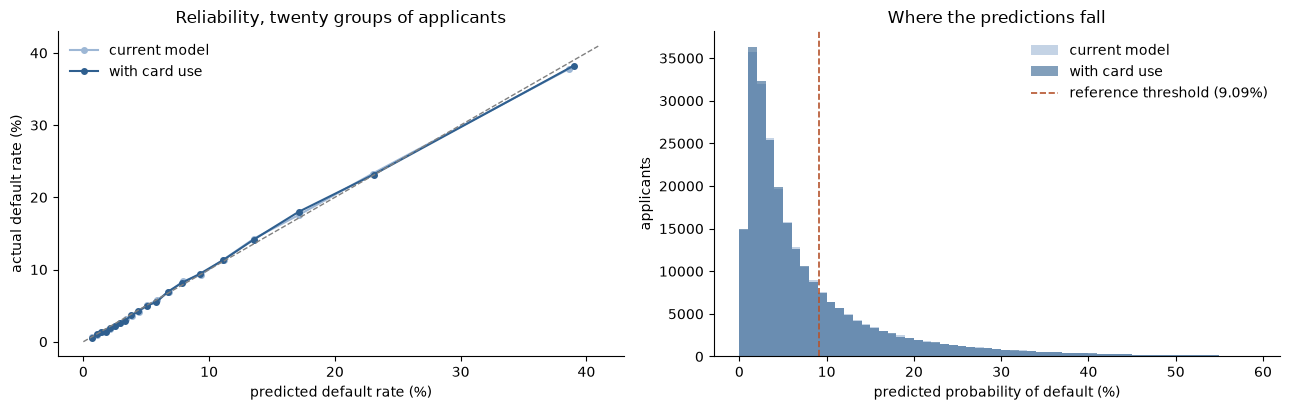

In [19]:
def reliability(p, bins=20):
    order = np.argsort(p)
    groups = np.array_split(order, bins)
    table = pd.DataFrame({'predicted_pct': [p[g].mean() * 100 for g in groups], 'actual_pct': [y_arr[g].mean() * 100 for g in groups], 'applicants': [len(g) for g in groups]})
    table['gap'] = table['predicted_pct'] - table['actual_pct']
    return table

def calibration_error(p, bins=20):
    t = reliability(p, bins)
    return float((t['gap'].abs() * t['applicants']).sum() / t['applicants'].sum()), float(t['gap'].abs().max())

report = {}
for label, p in {'current model': p_old, 'with card use': p_new, 'with card use, before calibration': final_run['oof']}.items():
    error, worst = calibration_error(p)
    report[label] = {'mean_prediction_pct': p.mean() * 100, 'actual_pct': y_arr.mean() * 100, 'calibration_error_pts': error, 'largest_gap_in_any_twentieth_pts': worst}
print(pd.DataFrame(report).T.to_string(float_format=lambda v: f'{v:.3f}'))

tenths = pd.DataFrame({'current: predicted': reliability(p_old, 10)['predicted_pct'], 'current: actual': reliability(p_old, 10)['actual_pct'],
                       'new: predicted': reliability(p_new, 10)['predicted_pct'], 'new: actual': reliability(p_new, 10)['actual_pct']})
tenths.index = [f'tenth {i + 1}' for i in range(10)]
print('\npredicted and actual default rate (%) by tenth of applicants, safest first:')
print(tenths.to_string(float_format=lambda v: f'{v:.2f}'))
print(f"\nthe new model spreads applicants further: safest tenth {tenths.iloc[0, 3]:.2f}% against {tenths.iloc[0, 1]:.2f}%, riskiest tenth {tenths.iloc[-1, 3]:.2f}% against {tenths.iloc[-1, 1]:.2f}%")
print(f"share of all defaults in the riskiest tenth: {tenths.iloc[-1, 1] / tenths['current: actual'].sum():.1%} -> {tenths.iloc[-1, 3] / tenths['new: actual'].sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for label, p, colour in [('current model', p_old, '#9db7d5'), ('with card use', p_new, '#2f5f8f')]:
    t = reliability(p)
    axes[0].plot(t['predicted_pct'], t['actual_pct'], marker='o', markersize=4, label=label, color=colour)
limit = max(reliability(p_new)['predicted_pct'].max(), reliability(p_new)['actual_pct'].max()) * 1.05
axes[0].plot([0, limit], [0, limit], color='grey', linestyle='--', linewidth=1)
axes[0].set_xlabel('predicted default rate (%)'); axes[0].set_ylabel('actual default rate (%)'); axes[0].set_title('Reliability, twenty groups of applicants'); axes[0].legend(frameon=False)
axes[1].hist(p_old * 100, bins=np.arange(0, 60, 1), alpha=0.6, label='current model', color='#9db7d5')
axes[1].hist(p_new * 100, bins=np.arange(0, 60, 1), alpha=0.6, label='with card use', color='#2f5f8f')
axes[1].axvline(THRESHOLD * 100, color='#b5542d', linestyle='--', linewidth=1.2, label=f'reference threshold ({THRESHOLD:.2%})')
axes[1].set_xlabel('predicted probability of default (%)'); axes[1].set_ylabel('applicants'); axes[1].set_title('Where the predictions fall'); axes[1].legend(frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

In [20]:
age = -X_dev['DAYS_BIRTH'].values / 365.25
calibration_groups = {
    'no card': ~has_card, 'a card': has_card,
    'never a balance': GROUPS['   never a balance'], 'over the limit at some time': GROUPS['   over the limit at some time'],
    'a card over 90% used at the application': GROUPS['   a card over 90% used at the application'], 'cash withdrawals in over 30% of months': GROUPS['   cash withdrawals in over 30% of months'],
    'never a cash withdrawal': GROUPS['   never a cash withdrawal'], 'paid under the minimum in over 30% of due months': (cc('SHARE_UNDER_MIN') > 0.3).values,
    'late by over 5 days at some time': (X_dev['INST' + '_SHARE_LATE_5D'] > 0).values, 'a penalty charge in the last 24 months': (X_dev['INST' + '_N_PENALTIES_24M'] > 0).values,
    'no bureau record': ~(X_dev['BUREAU_N_CREDITS'] > 0).values, 'men': (X_dev['CODE_GENDER'] == 'M').values, 'women': (X_dev['CODE_GENDER'] == 'F').values,
    'under 30': age < 30, 'over 60': age >= 60, 'cash loans': (X_dev['NAME_CONTRACT_TYPE'] == 'Cash loans').values, 'revolving loans': (X_dev['NAME_CONTRACT_TYPE'] == 'Revolving loans').values,
}
rows = {}
for label, m in calibration_groups.items():
    actual = y_arr[m].mean()
    se = np.sqrt(actual * (1 - actual) / m.sum()) * 100
    rows[label] = {'applicants': int(m.sum()), 'actual_pct': actual * 100, 'current_model_pct': p_old[m].mean() * 100, 'new_model_pct': p_new[m].mean() * 100,
                   'gap_current_in_se': (p_old[m].mean() - actual) * 100 / se, 'gap_new_in_se': (p_new[m].mean() - actual) * 100 / se}
groups_table = pd.DataFrame(rows).T
print(groups_table.astype({'applicants': int}).to_string(float_format=lambda v: f'{v:,.2f}'))
print(f"\ngroups more than 2 standard errors off: {int((groups_table['gap_current_in_se'].abs() > 2).sum())} with the current model {list(groups_table.index[groups_table['gap_current_in_se'].abs() > 2])}, "
      f"{int((groups_table['gap_new_in_se'].abs() > 2).sum())} with the new one {list(groups_table.index[groups_table['gap_new_in_se'].abs() > 2])}")

                                                  applicants  actual_pct  current_model_pct  new_model_pct  gap_current_in_se  gap_new_in_se
no card                                               176325        7.84               7.85           7.89               0.19           0.89
a card                                                 69683        8.67               8.85           8.69               1.62           0.18
never a balance                                        21946        5.44               6.14           5.64               4.63           1.34
over the limit at some time                            30078       11.84              11.00          11.71              -4.52          -0.68
a card over 90% used at the application                19339       14.89              13.36          14.50              -5.98          -1.53
cash withdrawals in over 30% of months                 12729       14.80              13.22          14.90              -5.01           0.31
never a cash 

In [21]:
from scipy.stats import ks_2samp

def outcome(p, ratio):
    t = 1 / (1 + ratio)
    declined, bad = p >= t, y_arr == 1
    missed, wrongly = int((~declined & bad).sum()), int((declined & ~bad).sum())
    return {'threshold': t, 'approved_pct': (~declined).mean() * 100, 'defaults_caught_pct': (declined & bad).sum() / bad.sum() * 100,
            'default_rate_among_approved_pct': missed / (~declined).sum() * 100, 'good_applicants_declined_pct': wrongly / (~bad).sum() * 100,
            'cost_per_1000_applicants': (ratio * missed + wrongly) / len(p) * 1000}

rows = {}
for ratio in [5, 10, 20]:
    a, b = outcome(p_old, ratio), outcome(p_new, ratio)
    blanket = min(ratio * y_arr.mean(), 1 - y_arr.mean()) * 1000            # the better of approving everyone and declining everyone
    for label, o in [('current model', a), ('with card use', b)]:
        rows[(f'ratio {ratio}', label)] = {**o, 'saving_against_no_model_pct': (1 - o['cost_per_1000_applicants'] / blanket) * 100}
    rows[(f'ratio {ratio}', 'change')] = {k: b[k] - a[k] for k in a} | {'saving_against_no_model_pct': (a['cost_per_1000_applicants'] - b['cost_per_1000_applicants']) / blanket * 100}
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f'{v:,.3f}'))

ref_old, ref_new = outcome(p_old, 10), outcome(p_new, 10)
assert abs(ref_old['threshold'] - THRESHOLD) < 1e-4
d_old, d_new, bad = p_old >= THRESHOLD, p_new >= THRESHOLD, y_arr == 1
print(f"\nat the reference threshold of {THRESHOLD:.4f}:")
print(pd.DataFrame({'current model': {'approved, repaid': int((~d_old & ~bad).sum()), 'approved, defaulted': int((~d_old & bad).sum()), 'declined, repaid': int((d_old & ~bad).sum()), 'declined, defaulted': int((d_old & bad).sum())},
                    'with card use': {'approved, repaid': int((~d_new & ~bad).sum()), 'approved, defaulted': int((~d_new & bad).sum()), 'declined, repaid': int((d_new & ~bad).sum()), 'declined, defaulted': int((d_new & bad).sum())}}
                   ).assign(change=lambda t: t['with card use'] - t['current model']).to_string())
print(f"\ncost per 1,000 applicants at a ratio of 10: {ref_old['cost_per_1000_applicants']:.1f} -> {ref_new['cost_per_1000_applicants']:.1f} ({(ref_new['cost_per_1000_applicants'] / ref_old['cost_per_1000_applicants'] - 1):+.1%})")
print(f"applicants whose decision changes: {(d_old != d_new).mean():.1%}; newly declined default at {y_arr[d_new & ~d_old].mean():.1%}, newly approved at {y_arr[~d_new & d_old].mean():.1%}")

ks = lambda p: ks_2samp(p[bad], p[~bad]).statistic
print(f"KS statistic: {ks(p_old):.4f} -> {ks(p_new):.4f}")
by_fold = pd.DataFrame({k: {'current model': (10 * (~d_old & bad)[dev_fold == k].sum() + (d_old & ~bad)[dev_fold == k].sum()) / (dev_fold == k).sum() * 1000,
                            'with card use': (10 * (~d_new & bad)[dev_fold == k].sum() + (d_new & ~bad)[dev_fold == k].sum()) / (dev_fold == k).sum() * 1000} for k in range(N_SPLITS)}).T
by_fold['change'] = by_fold['with card use'] - by_fold['current model']
print('\ncost per 1,000 applicants at a ratio of 10, by fold:')
print(by_fold.round(1).T.to_string())
print(f"lower cost with card use in {int((by_fold['change'] < 0).sum())} of 5 folds")

                        threshold  approved_pct  defaults_caught_pct  default_rate_among_approved_pct  good_applicants_declined_pct  cost_per_1000_applicants  saving_against_no_model_pct
ratio 5  current model      0.167        87.081               44.496                            5.145                        10.146                   317.303                       21.391
         with card use      0.167        87.070               44.935                            5.106                        10.119                   315.295                       21.888
         change             0.000        -0.011                0.438                           -0.040                        -0.026                    -2.008                        0.497
ratio 10 current model      0.091        71.799               68.384                            3.555                        24.672                   482.041                       40.289
         with card use      0.091        72.003               68.

KS statistic: 0.4416 -> 0.4454



cost per 1,000 applicants at a ratio of 10, by fold:
                   0      1      2      3      4
current model  488.7  487.4  480.0  476.0  478.1
with card use  487.8  485.4  477.4  476.7  472.7
change          -0.9   -2.0   -2.6    0.7   -5.4
lower cost with card use in 4 of 5 folds


In [22]:
fair_groups = {'gender': {'women': calibration_groups['women'], 'men': calibration_groups['men']},
               'age': {'under 30': age < 30, '30 to 45': (age >= 30) & (age < 45), '45 to 60': (age >= 45) & (age < 60), 'over 60': age >= 60},
               'card': {'no card': ~has_card, 'a card': has_card},
               'card use': {'never a balance': calibration_groups['never a balance'], 'over the limit at some time': calibration_groups['over the limit at some time']}}
rows = {}
for segment, members in fair_groups.items():
    old_rates = {g: (~d_old)[m].mean() for g, m in members.items()}
    new_rates = {g: (~d_new)[m].mean() for g, m in members.items()}
    for g, m in members.items():
        rows[(segment, g)] = {'applicants': int(m.sum()), 'default_pct': y_arr[m].mean() * 100, 'approved_current_pct': old_rates[g] * 100, 'approved_new_pct': new_rates[g] * 100,
                              'ratio_to_highest_current': old_rates[g] / max(old_rates.values()), 'ratio_to_highest_new': new_rates[g] / max(new_rates.values())}
print(pd.DataFrame(rows).T.astype({'applicants': int}).to_string(float_format=lambda v: f'{v:,.3f}'))

                                      applicants  default_pct  approved_current_pct  approved_new_pct  ratio_to_highest_current  ratio_to_highest_new
gender   women                            161887        7.001                76.466            76.589                     1.000                 1.000
         men                               84119       10.136                62.818            63.177                     0.822                 0.825
age      under 30                          36281       11.480                55.158            55.459                     0.639                 0.643
         30 to 45                          98993        9.044                68.194            68.475                     0.790                 0.794
         45 to 60                          82624        6.491                78.482            78.636                     0.909                 0.911
         over 60                           28110        4.906                86.329            86.28

### Stage 6 and 7 findings

**The settings do not move.** No share of features per tree meets the conditions: 40% is 0.00008 higher, 20% is 0.0007 lower in every fold. The tree curve peaks at 4,500 trees, 0.00007 above 3,500. Both stay where they are, and the gain is like for like: **0.0016** (standard error 0.0001, 5 of 5 folds).

**Calibrated, the model is better on every measure, in every fold**

| Measure | Current model | With card use | Change | Folds better |
|---|---:|---:|---:|---:|
| ROC AUC | 0.7932 | 0.7948 | +0.0016 | 5 of 5 |
| PR AUC | 0.2848 | 0.2879 | +0.0031 | 5 of 5 |
| Log loss | 0.2353 | 0.2347 | -0.0006 | 5 of 5 |
| Brier score | 0.0656 | 0.0655 | -0.0002 | 5 of 5 |

- The calibration method still fits (correcting slopes from 0.97 to 1.02), and the overall calibration error is 0.29 points, as before.

**The card gaps close**

| Group | Applicants | Actual | Current model | New model |
|---|---:|---:|---:|---:|
| A card over 90% used at the application | 19,339 | 14.9% | 13.4% | 14.5% |
| Cash withdrawals in over 30% of months | 12,729 | 14.8% | 13.2% | 14.9% |
| Over the limit at some time | 30,078 | 11.8% | 11.0% | 11.7% |
| Never a cash withdrawal | 28,548 | 5.9% | 6.8% | 6.0% |
| Never a balance | 21,946 | 5.4% | 6.1% | 5.6% |

- The current model was more than two standard errors off for five card groups. The new model is off for none of the 17 groups tested. As before, the groups were chosen knowing where the current model was weak.
- Missed minimum payments, which notebook 11 found to say nothing, were already priced correctly by the current model (11.5% for 11.6%).

**At the reference threshold the effect is small**
- The model approves 501 more good applicants and catches exactly the same number of defaults. The cost per 1,000 applicants falls from 482.0 to 480.0, by 0.4%, in 4 of 5 folds. At cost ratios of 5 and 20 it falls by 0.6% and 0.2%.
- That is smaller than for any adopted table so far (2% to 2.6% each). The card features help most where card holders are, and card holders are 28% of applicants.

**Approval rates**
- Gender and age gaps are unchanged. Card holders are now approved slightly more than before relative to others (0.96 against 0.94).
- Applicants who have been over their card limit are approved at 0.70 times the rate of those who never carried a balance, down from 0.75. They default at 11.8% against 5.4%. As with late payment in notebook 08, this is the applicant's own conduct, recorded by the lender.

**Leakage check.** Calibration is nested in the training folds; method and threshold are unchanged from notebook 02. All figures are out of fold. The holdout was not used.

## Stage 8: Explainability

A shorter version of notebook 08's stage 8: what share of the model the card features carry, which way the three of them push, and how often they lead a decline. The model is fitted on the development set with calibration, and a sample of 20,000 applicants is explained with exact contributions (SHAP values) in calibrated log-odds.

In [23]:
import hashlib, joblib
MODEL_DIR = CACHE_DIR / 'models'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

def fitted(tag, build):
    path = MODEL_DIR / f'{tag}.joblib'
    if path.exists():
        return joblib.load(path), True
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        model = build()
    joblib.dump(model, path, compress=3)
    return model, False

def model_tag(prefix, features, params, trees, rows):
    spec = {'features': list(features), 'params': {k: repr(v) for k, v in sorted(params.items())}, 'trees': trees, 'rate': LEARNING_RATE, 'rows': rows, 'seed': SEED,
            'module': hashlib.md5(Path('../src/models/pipeline.py').read_bytes()).hexdigest(), 'versions': [lightgbm.__version__, sklearn.__version__]}
    return prefix + '_' + hashlib.md5(json.dumps(spec, sort_keys=True).encode()).hexdigest()[:16]

started = time.time()
new_model, loaded = fitted(model_tag('dev_with_cards', CHOSEN_FEATURES, FINAL_PARAMS, FINAL_TREES, 'dev'), lambda: make_pipeline(CHOSEN_FEATURES, TEXT_FEATURES, CalibratedModel(MODEL(), method='platt')).fit(X_dev, y_arr))
print(f"model fitted on the development set: {'loaded' if loaded else f'{(time.time() - started) / 60:.1f} minutes'}")
sample_rows = np.sort(np.random.default_rng(SEED).choice(len(X_dev), size=20_000, replace=False))
X_sample, y_sample = X_dev.iloc[sample_rows], y_arr[sample_rows]
prepared = new_model.named_steps['preprocess'].transform(X_sample)
step = new_model.named_steps['model']
line_new = (float(step.calibrator_.coef_[0, 0]), float(step.calibrator_.intercept_[0]))
raw = step.model_.booster_.predict(prepared, pred_contrib=True)
shap_new = pd.DataFrame(line_new[0] * raw[:, :-1], columns=list(prepared.columns), index=X_sample.index)
p_fit = new_model.predict_proba(X_sample)[:, 1]
rebuilt = 1 / (1 + np.exp(-(shap_new.sum(axis=1).values + line_new[0] * raw[0, -1] + line_new[1])))
print(f"contributions rebuild the probability to within {np.abs(rebuilt - p_fit).max():.1e}")
assert np.abs(rebuilt - p_fit).max() < 1e-9

source_of = {c: k for k, members in SOURCES.items() for c in members}
source_of.update({c: 'credit card' for c in KEPT_CC})
size = shap_new.abs().mean()
shares = (size.groupby(pd.Series(source_of)).sum() / size.sum() * 100).sort_values(ascending=False)
print('\nshare of the model\'s total contribution, by table (%):')
print(shares.round(2).to_string())
top = size.sort_values(ascending=False)
print('\nwhere the card features rank among the 111:', {short(c): int(list(top.index).index(c)) + 1 for c in KEPT_CC})

rows = {}
for c in KEPT_CC:
    v, contribution = X_sample[c], shap_new[c]
    has = v.notna()
    if (v[has] > 0).mean() < 0.5:
        groups = pd.Series(np.where(v[has] > 0, 'above zero', 'zero'), index=v[has].index)
    else:
        groups = pd.qcut(v[has].rank(method='first'), 3, labels=['lowest third', 'middle', 'highest third'])
    by = contribution[has].groupby(groups, observed=True).mean()
    rows[short(c)] = {**{f'odds x, {k}': np.exp(val) for k, val in by.items()}, 'odds x, no card': np.exp(contribution[~has].mean()), 'card holders in the sample': int(has.sum())}
print('\naverage odds multiplier from each card feature:')
print(pd.DataFrame(rows).T.to_string(float_format=lambda v: f'{v:,.3f}'))

declined = p_fit >= THRESHOLD
family_push = pd.DataFrame({k: shap_new[[c for c in shap_new.columns if source_of.get(c) == k]].sum(axis=1) for k in shares.index})
main = family_push[declined].idxmax(axis=1).value_counts(normalize=True) * 100
card_declined = declined & X_sample[KEPT_CC].notna().any(axis=1).values
print(f"\ndeclined in the sample: {declined.mean():.1%}; main reason, by table (%):")
print(main.round(2).to_string())
print(f"among declined card holders ({int(card_declined.sum()):,}), the card features are the main reason for {(family_push[card_declined].idxmax(axis=1) == 'credit card').mean():.1%} and push risk up for {(family_push.loc[card_declined, 'credit card'] > 0).mean():.1%}")

model fitted on the development set: loaded


contributions rebuild the probability to within 2.9e-15

share of the model's total contribution, by table (%):
application              52.47
previous applications    15.76
instalment payments      15.61
credit bureau            13.72
credit card               2.44

where the card features rank among the 111: {'N_ATM_12M': 43, 'BALANCE_LATEST': 44, 'SHARE_OVER_LIMIT': 56}

average odds multiplier from each card feature:
                  odds x, above zero  odds x, zero  odds x, no card  card holders in the sample
N_ATM_12M                      1.205         0.952            0.988                   5,643.000
BALANCE_LATEST                 1.185         0.943            0.992                   5,560.000
SHARE_OVER_LIMIT               1.091         0.933            0.998                   5,589.000

declined in the sample: 27.6%; main reason, by table (%):
application              73.51
previous applications    10.28
instalment payments       7.22
credit bureau             4.52
credit c

## Stage 9: Outputs

Refit on all 307,511 training applicants, save the model, and write two submission files. The holdout applicants are used as training rows only, and nothing is scored on them.

The second file is the diagnostic: the same recipe with the three features that carry a warning (`CC_LIMIT_LATEST`, `CC_SHARE_ATM`, `CC_N_DEMAND`), added back. It is not a candidate.

In [24]:
import subprocess, tempfile, scipy
from scipy.stats import spearmanr

def load_joined(which):
    app = pd.read_parquet(f'{PROCESSED}/application_{which}_features.parquet')
    app['REGION_RATING_CLIENT_W_CITY'] = app['REGION_RATING_CLIENT_W_CITY'].astype(float)
    for name in ['bureau', 'previous', 'installments', 'credit_card']:
        part = pd.read_parquet(f'{PROCESSED}/{name}_{which}_features.parquet')
        assert app.index.equals(part.index)
        app = app.join(part, how='left')
    return app

train_all = load_joined('train')
X_all, y_all = train_all.drop(columns='TARGET'), train_all['TARGET'].values
X_test = load_joined('test')
del train_all
checks = {
    'all 307,511 training applicants, 24,825 defaults': len(X_all) == 307511 and int(y_all.sum()) == 24825,
    'the development rows are unchanged': X_all.loc[X_dev.index, CHOSEN_FEATURES].equals(X_dev[CHOSEN_FEATURES]),
    'test: 48,744 applicants, none in train, every feature present': len(X_test) == 48744 and len(X_test.index.intersection(X_all.index)) == 0 and set(CHOSEN_FEATURES) <= set(X_test.columns),
    'the card test file is the one notebook 11 saved (checksum)': sha(f'{PROCESSED}/credit_card_test_features.parquet') == meta['credit_card']['tables']['test']['sha256'],
}
for name, ok in checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(checks.values())

final_recipe = lambda features: make_pipeline(features, TEXT_FEATURES, CalibratedModel(MODEL(), method='platt'))
started = time.time()
production, loaded = fitted(model_tag('all_train_with_cards', CHOSEN_FEATURES, FINAL_PARAMS, FINAL_TREES, 'all train'), lambda: final_recipe(CHOSEN_FEATURES).fit(X_all, y_all))
prod_step = production.named_steps['model']
PROD_A, PROD_B = float(prod_step.calibrator_.coef_[0, 0]), float(prod_step.calibrator_.intercept_[0])
print(f"\nrefitted on all of train: {'loaded' if loaded else f'{(time.time() - started) / 60:.1f} minutes'}; calibration {line_new[0]:.4f}, {line_new[1]:.4f} on the development set -> {PROD_A:.4f}, {PROD_B:.4f}")
p_test = production.predict_proba(X_test)[:, 1]
p_test_dev = new_model.predict_proba(X_test)[:, 1]
previous_submission = pd.read_csv('../artifacts/submissions/submission_with_installments.csv').set_index('SK_ID_CURR')['TARGET'].reindex(X_test.index).values
test_card = X_test[KEPT_CC].notna().any(axis=1).values
print(pd.Series({'rank correlation, refitted against development-fitted': spearmanr(p_test, p_test_dev)[0],
                 'same decision at the reference threshold (%)': ((p_test >= THRESHOLD) == (p_test_dev >= THRESHOLD)).mean() * 100,
                 'average prediction (%)': p_test.mean() * 100, 'average prediction of notebook 08\'s submission (%)': previous_submission.mean() * 100,
                 'rank correlation with notebook 08\'s submission': spearmanr(p_test, previous_submission)[0],
                 'same decision as notebook 08\'s submission (%)': ((p_test >= THRESHOLD) == (previous_submission >= THRESHOLD)).mean() * 100,
                 'test applicants with a card (%)': test_card.mean() * 100}).round(4).to_string())

PASS  all 307,511 training applicants, 24,825 defaults
PASS  the development rows are unchanged
PASS  test: 48,744 applicants, none in train, every feature present
PASS  the card test file is the one notebook 11 saved (checksum)

refitted on all of train: loaded; calibration 0.9961, -0.6370 on the development set -> 1.0049, -0.6318


rank correlation, refitted against development-fitted     0.9896
same decision at the reference threshold (%)             96.6929
average prediction (%)                                    7.4797
average prediction of notebook 08's submission (%)        7.5371
rank correlation with notebook 08's submission            0.9892
same decision as notebook 08's submission (%)            96.7032
test applicants with a card (%)                          34.1642


In [25]:
warnings.filterwarnings('ignore', category=pd.errors.PerformanceWarning)
SAVE_DIR = Path('../artifacts/model_with_credit_cards')
SAVE_DIR.mkdir(parents=True, exist_ok=True)
prod_step.model_.booster_.save_model(str(SAVE_DIR / 'model.txt'))
file_sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
levels = production.named_steps['preprocess'].named_steps['encode'].categories_
saved_meta = {
    'name': 'Home Credit default risk, application, credit bureau, previous application, instalment payment and credit card tables',
    'predicts': 'probability that the applicant has payment difficulties (TARGET = 1)',
    'files': {'model': 'model.txt', 'model_sha256': file_sha(SAVE_DIR / 'model.txt')},
    'features': CHOSEN_FEATURES,
    'feature_sources': {**SOURCES, 'credit card': list(KEPT_CC)},
    'text_feature_levels': {c: list(levels[c]) for c in CHOSEN_FEATURES if c in TEXT_FEATURES},
    'inputs': {**recipe['inputs'], 'credit card features': 'data/processed/credit_card_*_features.parquet (notebook 11, src/features/credit_card.py)'},
    'calibration': {'method': 'Platt scaling', 'slope': PROD_A, 'intercept': PROD_B, 'formula': recipe['calibration']['formula']},
    'decision': recipe['decision'],
    'training': {'rows': int(len(X_all)), 'defaults': int(y_all.sum()), 'trees': int(FINAL_TREES), 'learning_rate': float(LEARNING_RATE), 'seed': SEED,
                 'lightgbm_settings': {k: (float(v) if isinstance(v, float) else int(v)) for k, v in FINAL_PARAMS.items()}},
    'evidence': {'note': 'Cross-validated on the development set. The saved model was fitted on all of train and has not itself been scored. The holdout has not been opened for this model.',
                 'cross_validation': {'roc_auc': float(final_cal['mean']['roc_auc']), 'pr_auc': float(final_cal['mean']['pr_auc']), 'log_loss': float(final_cal['mean']['log_loss'])},
                 'model_with_installments': {'roc_auc': float(baseline_cal['mean']['roc_auc']), 'log_loss': float(baseline_cal['mean']['log_loss'])},
                 'gain_from_credit_card_features_like_for_like': float(compare(final_run, baseline_same)['mean_difference'])},
    'warnings': recipe['warnings'],
    'left_out': {**{c: 'Carries a warning from notebook 11 and adds nothing on the development folds (notebook 12, stage 4).' for c in SHIFT_WARNED},
                 **{c: 'Not chosen by the pruning of notebook 12, stage 5.' for c in CANDIDATES if c not in KEPT_CC},
                 'POS_CASH_balance features': 'Tested in notebook 10 and left out: no gain.'},
    'known_limits': recipe.get('known_limits', []),
    'versions': recipe['versions'],
}
(SAVE_DIR / 'metadata.json').write_text(json.dumps(saved_meta, indent=2), encoding='utf-8')
sys.path.insert(0, '../src/models')
from scoring import load_model
loaded_model = load_model(SAVE_DIR)
direct = loaded_model.predict_proba(X_test)
with tempfile.TemporaryDirectory() as tmp:
    table, out_csv = Path(tmp) / 't.parquet', Path(tmp) / 's.csv'
    X_test.to_parquet(table)
    run_outside = subprocess.run([sys.executable, '../src/models/scoring.py', str(SAVE_DIR), str(table), str(out_csv)], capture_output=True, text=True)
    assert run_outside.returncode == 0, run_outside.stderr[-2000:]
    outside = pd.read_csv(out_csv).set_index('SK_ID_CURR')['TARGET']
earlier = {name: json.loads(Path(f'../artifacts/{name}/metadata.json').read_text(encoding='utf-8'))['files']['model_sha256'] for name in ['final_model', 'model_with_bureau', 'model_with_previous', 'model_with_installments']}
save_checks = {
    'loaded in this process: equal to the pipeline': float(np.abs(direct - p_test).max()) < 1e-9,
    'a separate process gives the same predictions': outside.index.equals(X_test.index) and float(np.abs(outside.values - p_test).max()) < 1e-9,
    'it uses its 111 features': len(loaded_model.features) == len(CHOSEN_FEATURES) == 111,
    'the four earlier models are untouched': all(file_sha(f'../artifacts/{n}/model.txt') == d for n, d in earlier.items()),
}
for name, ok in save_checks.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")
assert all(save_checks.values())

PASS  loaded in this process: equal to the pipeline
PASS  a separate process gives the same predictions
PASS  it uses its 111 features
PASS  the four earlier models are untouched


In [26]:
WITH_FLAGGED = CHOSEN_FEATURES + SHIFT_WARNED
started = time.time()
cv_flagged = run(WITH_FLAGGED, model=MODEL())
flag_effect = compare(cv_flagged, final_run)
CV_MAIN, CV_FLAGGED, CV_FLAG_EFFECT = float(final_run['mean']['roc_auc']), float(cv_flagged['mean']['roc_auc']), float(flag_effect['mean_difference'])
print(f"with the three warned features, cross-validated: {CV_FLAGGED:.5f}; adding them changes the score by {CV_FLAG_EFFECT:+.5f} (standard error {flag_effect['standard_error']:.5f}, better in {flag_effect['folds_better']} of 5 folds)")
production_flagged, _ = fitted(model_tag('all_train_with_cards_flagged', WITH_FLAGGED, FINAL_PARAMS, FINAL_TREES, 'all train'), lambda: final_recipe(WITH_FLAGGED).fit(X_all, y_all))
p_test_flagged = production_flagged.predict_proba(X_test)[:, 1]
print(f"two fits: {(time.time() - started) / 60:.1f} minutes")

WITH_INSTALMENTS = {'cv': float(baseline['mean']['roc_auc']), 'public': 0.79125, 'private': 0.79337}
CV_GAIN = CV_MAIN - WITH_INSTALMENTS['cv']
CARRY_FLOOR = round(CV_MAIN - 0.010, 4)
GAIN_FLOOR = round(WITH_INSTALMENTS['private'] + CV_GAIN / 2, 4)
print('\nexpectations, fixed before submitting:')
print(f"  1. The score carries over if the private score is {CARRY_FLOOR:.4f} or higher (within 0.010 of the cross-validated {CV_MAIN:.4f}).")
print(f"  2. The gain carries over if the private score is {GAIN_FLOOR:.4f} or higher: notebook 08's {WITH_INSTALMENTS['private']:.5f} plus half the cross-validated gain of {CV_GAIN:+.4f}.")
print(f"  3. The warned features: a private difference between the two files under {NOISE_FLOOR:.4f} either way agrees with the folds ({CV_FLAG_EFFECT:+.4f}).")
print(f"     If the diagnostic scores higher by more, leaving them out cost something on the test file; if lower by more, they hurt there.")

SUBMISSION_DIR = Path('../artifacts/submissions')
existing = {f.name: file_sha(f) for f in SUBMISSION_DIR.iterdir() if not f.name.startswith('submission_with_credit_cards')}
sample_submission = pd.read_csv(f'{RAW}/sample_submission.csv')
for filename, predictions in {'submission_with_credit_cards.csv': p_test, 'submission_with_credit_cards_with_flagged_features.csv': p_test_flagged}.items():
    frame = pd.DataFrame({'SK_ID_CURR': X_test.index.values, 'TARGET': predictions}).set_index('SK_ID_CURR').loc[sample_submission['SK_ID_CURR']].reset_index()
    frame.to_csv(SUBMISSION_DIR / filename, index=False)
    back = pd.read_csv(SUBMISSION_DIR / filename)
    ok = (list(back.columns) == ['SK_ID_CURR', 'TARGET'] and len(back) == 48744 and (back['SK_ID_CURR'].values == sample_submission['SK_ID_CURR'].values).all()
          and back['TARGET'].between(0, 1, inclusive='neither').all() and np.allclose(back['TARGET'].values, frame['TARGET'].values, rtol=0, atol=1e-12))
    print(f"{'PASS' if ok else 'FAIL'}  {filename}: 48,744 rows, mean {back['TARGET'].mean():.4f}, declined at the reference threshold {(back['TARGET'] >= THRESHOLD).mean():.1%}")
    assert ok
print(f"rank correlation between the two files: {spearmanr(p_test, p_test_flagged)[0]:.4f}")
untouched = all(file_sha(SUBMISSION_DIR / n) == d for n, d in existing.items())
print(f"the {len(existing)} earlier submission files are untouched: {untouched}")
assert untouched
del X_all, y_all

with the three warned features, cross-validated: 0.79490; adding them changes the score by +0.00015 (standard error 0.00005, better in 5 of 5 folds)


two fits: 0.1 minutes

expectations, fixed before submitting:
  1. The score carries over if the private score is 0.7848 or higher (within 0.010 of the cross-validated 0.7948).
  2. The gain carries over if the private score is 0.7942 or higher: notebook 08's 0.79337 plus half the cross-validated gain of +0.0016.
  3. The warned features: a private difference between the two files under 0.0005 either way agrees with the folds (+0.0001).
     If the diagnostic scores higher by more, leaving them out cost something on the test file; if lower by more, they hurt there.


PASS  submission_with_credit_cards.csv: 48,744 rows, mean 0.0748, declined at the reference threshold 25.9%


PASS  submission_with_credit_cards_with_flagged_features.csv: 48,744 rows, mean 0.0746, declined at the reference threshold 25.9%
rank correlation between the two files: 0.9951
the 8 earlier submission files are untouched: True


In [27]:
KAGGLE_SCORES = {
    'submission_with_credit_cards.csv': {'public': 0.79326, 'private': 0.79428},
    'submission_with_credit_cards_with_flagged_features.csv': {'public': 0.79278, 'private': 0.79439},
}
KAGGLE_ENTERED = all(v is not None for s in KAGGLE_SCORES.values() for v in s.values())
if not KAGGLE_ENTERED:
    print('Not submitted yet. The three expectations above are untested.')
else:
    main, second = KAGGLE_SCORES['submission_with_credit_cards.csv'], KAGGLE_SCORES['submission_with_credit_cards_with_flagged_features.csv']
    print(f"1. private {main['private']:.5f} against the floor {CARRY_FLOOR:.4f}: {'carries over' if main['private'] >= CARRY_FLOOR else 'does NOT carry over'} (private minus cross-validation {main['private'] - CV_MAIN:+.5f})")
    gain = main['private'] - WITH_INSTALMENTS['private']
    print(f"2. gain over notebook 08 on the private test set {gain:+.5f} (cross-validated {CV_GAIN:+.5f}); floor {GAIN_FLOOR:.4f}: {'carries over' if main['private'] >= GAIN_FLOOR else 'does NOT carry over in full'}")
    diff = second['private'] - main['private']
    print(f"3. diagnostic minus main on the private test set {diff:+.5f}: {'agrees with the folds' if abs(diff) < NOISE_FLOOR else ('leaving them out cost something' if diff > 0 else 'they hurt on the test file')}; public difference {second['public'] - main['public']:+.5f}")

1. private 0.79428 against the floor 0.7848: carries over (private minus cross-validation -0.00048)
2. gain over notebook 08 on the private test set +0.00091 (cross-validated +0.00160); floor 0.7942: carries over
3. diagnostic minus main on the private test set +0.00011: agrees with the folds; public difference -0.00048


### Stage 8 and 9 findings

**What the card features do in the model**
- The three card features carry 2.4% of the model's total contribution. They rank 43rd, 44th and 56th of 111. The application still carries 52%, and the three history tables 14% to 16% each.
- Each pushes the way the outcomes do. Cash withdrawals in the last year multiply the odds by 1.21 on average where there were any and by 0.95 where there were none; a balance at the application by 1.19 against 0.94; time over the limit by 1.09 against 0.93. For applicants without a card all three are close to neutral.
- Among declined card holders, the card features are the main reason for 14% and push risk up for 62%. These are reasons that can be said plainly: you are using most of your card limit, and you draw cash on it.

**Outputs**
- The model is refitted on all 307,511 training applicants and saved in `artifacts/model_with_credit_cards/`. It loads through the existing `src/models/scoring.py`, and a separate process gives the same predictions. The four earlier models are untouched.
- Against the development-fitted model on the test file: rank correlation 0.990, the same decision for 96.7% of applicants. Against notebook 08's submission: rank correlation 0.989.
- Added back to the final list, the three warned features change the cross-validated score by +0.00015, in all five folds but below the noise floor. The diagnostic file has them; the two files correlate at 0.995.

**Expectations, written before any score is seen**
1. The validation score carries over if the private score is **0.7848** or higher.
2. The gain carries over if the private score is **0.7942** or higher, which is notebook 08's private score plus half of the cross-validated gain.
3. A difference between the two files under 0.0005 either way agrees with the folds.

**Kaggle scores** (late submissions, read on 16 October 2026)

| Model | Cross-validation | Kaggle public | Kaggle private |
|---|---:|---:|---:|
| Application only (notebook 02) | 0.7685 | 0.7674 | 0.7638 |
| With bureau (notebook 04) | 0.7779 | 0.7741 | 0.7753 |
| With earlier applications (notebook 06) | 0.7856 | 0.7802 | 0.7842 |
| With the payment record (notebook 08) | 0.7932 | 0.7913 | 0.7934 |
| **With credit card use** | **0.7948** | **0.7933** | **0.7943** |
| The same, with the three warned features | 0.7949 | 0.7928 | 0.7944 |

1. **The validation score carries over.** The private score is 0.79428, far above the floor of 0.7848 and 0.0005 below cross-validation.
2. **The gain carries over, only just.** On the private test set credit card use adds 0.0009 to notebook 08's model, 57% of the cross-validated 0.0016. The floor, half of the cross-validated gain added to 0.79337, was 0.7942 as written (0.79417 unrounded), and the score is 0.79428. On the public score the gain is 0.0020, more than cross-validation said.
3. **The warned features agree with the folds.** The diagnostic is 0.00011 higher on the private score, under the noise floor, and 0.00048 lower on the public score. They neither help nor hurt measurably.
4. This is the smallest test-set gain of the four adopted tables, as it was the smallest in cross-validation. It is also the first where the private gain fell short of the cross-validated one, which fits notebook 11's warning that card features differ most between train and test.

## Stage 10: Conclusions

**The answer.** Yes, credit card use improves the model, by less than the earlier tables and in a narrower way.

| | Notebook 08 | With credit card use |
|---|---:|---:|
| ROC AUC, cross-validated | 0.7932 | 0.7948 (+0.0016) |
| PR AUC | 0.2848 | 0.2879 |
| Log loss | 0.2353 | 0.2347 |
| Card groups mis-predicted by over two standard errors | 5 | 0 |
| Cost per 1,000 applicants at the reference threshold | 482.0 | 480.0 |
| Kaggle private | 0.7934 | 0.7943 (+0.0009) |

- The gain meets all four conditions on three seeds, and scrambled card columns give nothing. By the honest in-fold measure for a list of three, it is 0.0014.
- It comes from **exposure**: how much of the limit is used, whether a balance is carried at the application, and cash withdrawals. Missed minimum payments and arrears on cards add nothing beyond the payment table.
- It is concentrated where cards are: +0.0054 within the 28% of applicants with one.
- **Three features out of fifteen are enough.** Fifteen card features, mostly empty and several weak, did slightly worse than four utilisation features alone, because each tree is offered a random 30% of the columns.

**Across the five history tables**

| Table | Notebooks | Cross-validated gain | Adopted |
|---|---|---:|---|
| Credit bureau | 03, 04 | +0.0094 | Yes |
| Earlier applications | 05, 06 | +0.0077 | Yes |
| Instalment payments | 07, 08 | +0.0075 | Yes |
| Monthly balances of cash and point-of-sale loans | 09, 10 | +0.0001 | No |
| Credit card balances | 11, 12 | +0.0016 | Yes |

**What I got wrong in this pair of notebooks**
- The redundancy rule of notebook 11 dropped the best single card feature for a near-copy with wider coverage. Pruning here ended up choosing three other features, and the applicants the dropped one described are placed as before, so it cost little. The rule's coverage criterion is still worth revisiting.
- Fixing the pruned list on the folds flattered it by 0.00016, four times more than in earlier notebooks. I report the honest figure beside it.

**Limits**
- Train and test differ more for card features than for any earlier table. The kept three tell the files apart less than the full set, and the Kaggle score is the check.
- The practical effect at the reference threshold is small: 501 more good applicants approved, the same defaults caught.
- Applicants who have been over their card limit are now approved at 0.70 times the rate of those who never carried a balance.
- The settings were tuned in notebook 02 for 55 features; there are now 111.

**What comes next**
1. Search the settings once, inside the folds, for the final 111-feature list.
2. Open the holdout once, for the final model.
